# TFM: Predicción temprana de la deserción estudiantil en educación superior

**Autoras:** Adelis Anet Padilla Piña y Laura Teresa Muñoz Sánchez  
**Directora:** Dra. María Aurora Martínez Rey  
**Máster Universitario en Inteligencia Artificial (UNIR)**

Cuaderno experimental reproducible que compara cinco clasificadores (regresión logística, árbol de decisión, Random Forest, XGBoost y CatBoost) en tres momentos de predicción. La clase positiva es `Dropout`; `Graduate` y `Enrolled` forman la clase negativa en el análisis principal. Se incluye un análisis de sensibilidad sin `Enrolled`.

**Resumen:**
1. Partición estratificada 80/20 (semilla 42). El conjunto de prueba no interviene en ninguna decisión.
2. Preprocesamiento y sobremuestreo aleatorio dentro de un `Pipeline` de imbalanced-learn, de modo que solo actúan sobre los datos de entrenamiento de cada ajuste.
3. Búsqueda aleatoria de hiperparámetros (`RandomizedSearchCV`) con validación interna estratificada de 3 pliegues, optimizando G-Mean.
4. Umbral de decisión elegido sobre probabilidades *out-of-fold* del entrenamiento (maximiza G-Mean; desempates por sensibilidad, precisión y cercanía a 0,5).
5. Validación cruzada anidada 10 × 3 que repite los pasos 2 a 4 dentro de cada pliegue externo. El G-Mean medio externo es el criterio de selección definido a priori.
6. Evaluación única en prueba, pruebas estadísticas, SHAP (XGBoost y regresión logística, global agregado por variable original y local) y análisis de equidad.

**Dataset:** Se descargan de Kaggle con KaggleHub y se verifican automáticamente.



## 1. Instalación de dependencias

Se fijan las versiones de las librerías de modelado. Al final, la sección 15 guarda `requirements.txt` con las versiones exactas del entorno ejecutado.

In [ ]:
%pip install -q "numpy==2.1.3" "pandas==2.2.3" "scikit-learn==1.6.1" "imbalanced-learn==0.13.0" "scipy==1.16.3" "xgboost==3.4.1" "catboost==1.2.10" "shap==0.54.1" "statsmodels==0.14.5" "matplotlib==3.10.0" "seaborn==0.13.2" "tabulate==0.9.0" kagglehub

## 2. Importaciones y configuración experimental

Todos los parámetros del experimento se concentran en esta celda. `FAST_MODE = True` reduce el presupuesto solo para comprobar que el cuaderno funciona; **los resultados de la memoria deben generarse con `FAST_MODE = False`**.

In [ ]:
import os, sys, json, random, warnings, platform, subprocess, hashlib, time, re, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone, BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (make_scorer, confusion_matrix, accuracy_score, balanced_accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, roc_curve, precision_recall_curve)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from scipy.stats import friedmanchisquare, rankdata, studentized_range, norm, spearmanr
from statsmodels.stats.contingency_tables import mcnemar
from IPython.display import display

# ---------------- Configuración ----------------
SEED = 42
TEST_SIZE = 0.20
N_OUTER = 10                 # pliegues externos de la validación cruzada anidada
N_INNER = 3                  # pliegues internos para la búsqueda de hiperparámetros
N_ITER = 10                  # configuraciones aleatorias evaluadas por búsqueda (idéntico en el modelo final y en cada pliegue externo)
THRESHOLD_CV_FINAL = 5       # pliegues para las probabilidades out-of-fold del umbral del modelo final
THRESHOLD_CV_NESTED = 3      # pliegues para el umbral dentro de cada pliegue externo
BALANCE_STRATEGY = "oversampling"   # "oversampling" (RandomOverSampler) o "class_weight" (ponderación de clases)
MAIN_SCENARIO = "after_first_semester"
RUN_ALL_SCENARIOS = True
RUN_SENSITIVITY_EXCLUDING_ENROLLED = True
SENSITIVITY_SCENARIO = MAIN_SCENARIO
RUN_SHAP = True
SHAP_BACKGROUND_SIZE = 100
N_BOOT = 1000
N_JOBS = -1                  # paralelismo de la búsqueda; los estimadores usan 1 hilo para evitar sobresuscripción
FAST_MODE = False

if FAST_MODE:
    N_OUTER, N_ITER, THRESHOLD_CV_FINAL, N_BOOT = 3, 2, 3, 100

OUTPUT_DIR = Path("resultados_tfm"); OUTPUT_DIR.mkdir(exist_ok=True)
FIG_DIR = OUTPUT_DIR / "figuras"; FIG_DIR.mkdir(exist_ok=True)
TAB_DIR = OUTPUT_DIR / "tablas"; TAB_DIR.mkdir(exist_ok=True)

random.seed(SEED); np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10})

MODEL_ORDER = ["Regresión logística", "Árbol de decisión", "Random Forest", "XGBoost", "CatBoost"]
SCENARIO_LABELS = {"at_enrollment": "Matrícula", "after_first_semester": "Primer semestre",
                   "after_second_semester": "Segundo semestre"}

def save_fig(name):
    """Guarda la figura activa en PNG (300 ppp) para insertarla en la memoria."""
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, bbox_inches="tight")
    print("Figura guardada:", path)

def save_table(df, name, index=False, decimals=4):
    """Guarda una tabla en CSV y en Markdown (para copiar en la memoria)."""
    df.to_csv(TAB_DIR / f"{name}.csv", index=index)
    try:
        (TAB_DIR / f"{name}.md").write_text(df.round(decimals).to_markdown(index=index), encoding="utf-8")
    except Exception:
        pass

print("Python:", sys.version.split()[0], "| Plataforma:", platform.platform())
print(f"Protocolo: CV anidada {N_OUTER}x{N_INNER}, n_iter={N_ITER}, balance={BALANCE_STRATEGY}, FAST_MODE={FAST_MODE}")

Python: 3.13.18 | Plataforma: Linux-6.6.159+-x86_64-with-glibc2.39
Protocolo: CV anidada 10x3, n_iter=10, balance=oversampling, FAST_MODE=False


## 3. Carga y validación de los datos

Los datos se descargan de Kaggle con KaggleHub: conjunto *Higher Education Predictors of Student Retention* (`thedevastator/higher-education-predictors-of-student-retention`), derivado de *Predict Students' Dropout and Academic Success* (Realinho et al., 2022). Esta versión contiene 34 variables predictoras y 1 variable objetivo.

Dimensiones (4.424 × 35), nombres de las columnas y distribución de `Target` (2.209 Graduate, 1.421 Dropout, 794 Enrolled).

In [ ]:
import kagglehub

KAGGLE_DATASET = "thedevastator/higher-education-predictors-of-student-retention"
TARGET_COL = "Target"
EXPECTED_SHAPE = (4424, 35)
EXPECTED_TARGET = {"Graduate": 2209, "Dropout": 1421, "Enrolled": 794}
EXPECTED_CONTENT_SHA256 = "3e9093c2a14254ba3b6851e13204dd53d31f43a63570d8ed61763c23a7a91abf"
EXPECTED_COLUMNS = [
    "Marital status", "Application mode", "Application order", "Course", "Daytime/evening attendance",
    "Previous qualification", "Nacionality", "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation", "Displaced", "Educational special needs", "Debtor",
    "Tuition fees up to date", "Gender", "Scholarship holder", "Age at enrollment", "International",
    *[f"Curricular units {s} sem ({k})" for s in ["1st", "2nd"]
      for k in ["credited", "enrolled", "evaluations", "approved", "grade", "without evaluations"]],
    "Unemployment rate", "Inflation rate", "GDP", "Target"]

def read_csv_flexible(path):
    df = pd.read_csv(path, sep=None, engine="python", encoding="utf-8-sig")
    df.columns = df.columns.str.strip()
    return df

def load_from_kaggle():
    folder = Path(kagglehub.dataset_download(KAGGLE_DATASET))
    for csv_path in sorted(folder.rglob("*.csv")):
        try:
            df = read_csv_flexible(csv_path)
        except Exception:
            continue
        if TARGET_COL in df.columns:
            return df, f"Kaggle: {KAGGLE_DATASET} ({csv_path.name})"
    raise FileNotFoundError("Ningún CSV descargado de Kaggle contiene la columna 'Target'.")

try:
    df_original, DATA_SOURCE = load_from_kaggle()
except Exception as e:
    print("No se pudo descargar de Kaggle:", type(e).__name__, e)
    if not Path("dataset.csv").exists():
        raise RuntimeError("Sin acceso a Kaggle y sin respaldo local: suba dataset.csv al panel de archivos de Colab.")
    df_original, DATA_SOURCE = read_csv_flexible("dataset.csv"), "Respaldo local: dataset.csv"


assert df_original.shape == EXPECTED_SHAPE, f"Dimensiones inesperadas: {df_original.shape}"
assert list(df_original.columns) == EXPECTED_COLUMNS, "Los nombres o el orden de las columnas no coinciden"
assert df_original[TARGET_COL].value_counts().to_dict() == EXPECTED_TARGET, "La distribución de Target no coincide"

source_sha256 = hashlib.sha256(df_original.to_csv(index=False).encode("utf-8")).hexdigest()
print("Fuente:", DATA_SOURCE)
print("Dimensiones:", df_original.shape)
print("SHA-256 del contenido:", source_sha256)
if source_sha256 == EXPECTED_CONTENT_SHA256:
    print("Huella verificada: los datos coinciden con la versión utilizada en el TFM.")
else:
    print("AVISO: la huella no coincide con la registrada. Las comprobaciones estructurales son correctas, "
          "pero conviene revisar si Kaggle ha publicado una versión distinta antes de usar los resultados.")
display(df_original[TARGET_COL].value_counts().rename("n").to_frame())

Using Colab cache for faster access to the 'higher-education-predictors-of-student-retention' dataset.
Fuente: Kaggle: thedevastator/higher-education-predictors-of-student-retention (dataset.csv)
Dimensiones: (4424, 35)
SHA-256 del contenido: 3e9093c2a14254ba3b6851e13204dd53d31f43a63570d8ed61763c23a7a91abf
Huella verificada: los datos coinciden con la versión utilizada en el TFM.


,n
Target,
Graduate,2209
Dropout,1421
Enrolled,794


## 4. Análisis exploratorio y diccionario de variables

Se genera la **tabla de variables** que pide la directora (nombre, descripción, tipo, tratamiento en los modelos y disponibilidad en cada momento de predicción), junto con calidad de datos, distribución del objetivo, tasas de abandono por categoría y correlación de Spearman entre variables cuantitativas.

Valores ausentes totales: 0 | Filas duplicadas: 0


,variable,tipo_pandas,n_valores_distintos,n_ausentes
0,Marital status,int64,6,0
1,Application mode,int64,18,0
2,Application order,int64,8,0
3,Course,int64,17,0
4,Daytime/evening attendance,int64,2,0
5,Previous qualification,int64,17,0
6,Nacionality,int64,21,0
7,Mother's qualification,int64,29,0
8,Father's qualification,int64,34,0
9,Mother's occupation,int64,32,0


,N.º,Variable,Descripción,Tipo,Tratamiento,Bloque,Categorías / rango,Usada en Matrícula,Usada en Primer semestre,Usada en Segundo semestre
0,1,Marital status,Estado civil del estudiante al matricularse,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Demográfico,6 categorías,Sí,Sí,Sí
1,2,Application mode,Vía o modalidad de acceso a la titulación,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Acceso y matrícula,18 categorías,Sí,Sí,Sí
2,3,Application order,Orden de preferencia de la titulación en la so...,Ordinal,Numérica (orden conservado); imputación por me...,Acceso y matrícula,0 a 9,Sí,Sí,Sí
3,4,Course,Titulación en la que se matricula el estudiante,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Acceso y matrícula,17 categorías,Sí,Sí,Sí
4,5,Daytime/evening attendance,"Régimen de asistencia (1 = diurno, 0 = vespert...",Categórica binaria,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Acceso y matrícula,2 categorías,Sí,Sí,Sí
5,6,Previous qualification,Nivel de la titulación académica previa,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Acceso y matrícula,17 categorías,Sí,Sí,Sí
6,7,Nacionality,Nacionalidad del estudiante,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Demográfico,21 categorías,Sí,Sí,Sí
7,8,Mother's qualification,Nivel de estudios de la madre,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Familiar,29 categorías,Sí,Sí,Sí
8,9,Father's qualification,Nivel de estudios del padre,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Familiar,34 categorías,Sí,Sí,Sí
9,10,Mother's occupation,Ocupación de la madre,Categórica nominal,"One-Hot en LR, DT, RF y XGBoost; categoría nat...",Familiar,32 categorías,Sí,Sí,Sí


34 variables predictoras: 17 categóricas (8 binarias), 1 ordinal, 16 numéricas.
Variables excluidas en el escenario principal (segundo semestre): ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']


,n,%
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


Figura guardada: resultados_tfm/figuras/fig_distribucion_objetivo.png


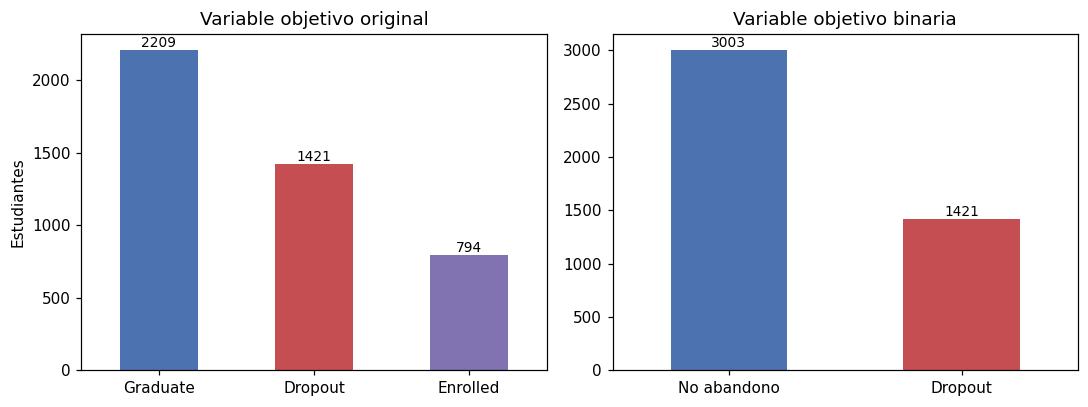

,Variable,Categorías (n ≥ 30),Tasa mínima (%),Tasa máxima (%),Amplitud (p.p.)
13,Tuition fees up to date,2,24.7,86.6,61.8
6,Mother's qualification,9,16.3,73.8,57.5
1,Application mode,12,11.4,61.2,49.7
7,Father's qualification,9,23.8,72.3,48.5
4,Previous qualification,7,16.7,64.2,47.5
8,Mother's occupation,11,27.1,72.9,45.8
9,Father's occupation,12,27.6,70.8,43.1
2,Course,16,15.4,55.3,39.9
12,Debtor,2,28.3,62.0,33.7
15,Scholarship holder,2,12.2,38.7,26.5


Figura guardada: resultados_tfm/figuras/fig_correlacion_spearman.png


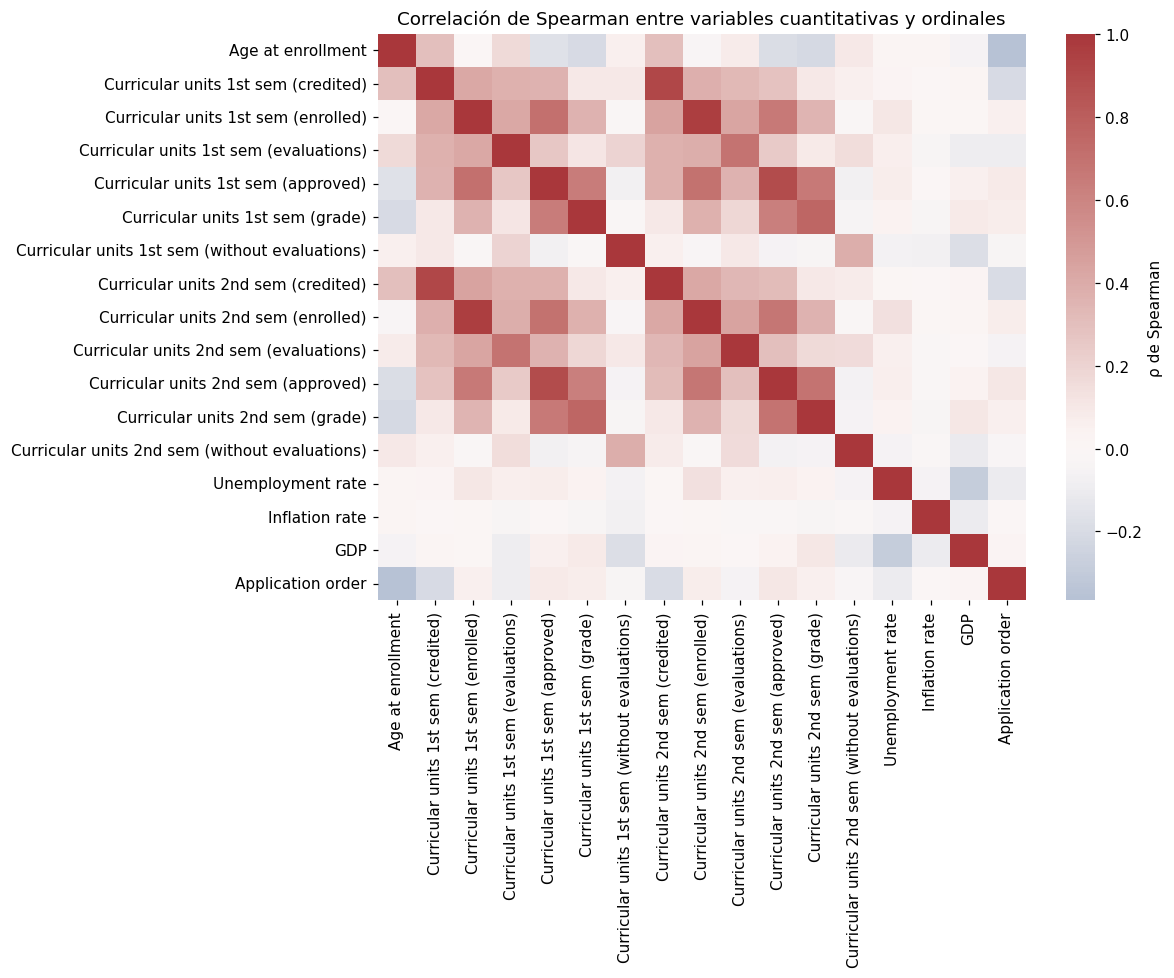

,Variable 1,Variable 2,ρ
0,Curricular units 1st sem (credited),Curricular units 2nd sem (credited),0.914
1,Curricular units 1st sem (enrolled),Curricular units 2nd sem (enrolled),0.962
2,Curricular units 1st sem (approved),Curricular units 2nd sem (approved),0.892


In [ ]:
# Calidad de los datos
eda_types = pd.DataFrame({
    "variable": df_original.columns,
    "tipo_pandas": [str(df_original[c].dtype) for c in df_original.columns],
    "n_valores_distintos": [df_original[c].nunique() for c in df_original.columns],
    "n_ausentes": [int(df_original[c].isna().sum()) for c in df_original.columns],
})
print("Valores ausentes totales:", int(df_original.isna().sum().sum()), "| Filas duplicadas:", int(df_original.duplicated().sum()))
display(eda_types)

# Clasificación de variables
categorical_vars = ["Marital status", "Application mode", "Course", "Daytime/evening attendance",
                    "Previous qualification", "Nacionality", "Mother's qualification", "Father's qualification",
                    "Mother's occupation", "Father's occupation", "Displaced", "Educational special needs",
                    "Debtor", "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
binary_vars = ["Daytime/evening attendance", "Displaced", "Educational special needs", "Debtor",
               "Tuition fees up to date", "Gender", "Scholarship holder", "International"]
ordinal_vars = ["Application order"]
numeric_vars = ["Age at enrollment",
                "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
                "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
                "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
                "Curricular units 2nd sem (credited)", "Curricular units 2nd sem (enrolled)",
                "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)",
                "Curricular units 2nd sem (grade)", "Curricular units 2nd sem (without evaluations)",
                "Unemployment rate", "Inflation rate", "GDP"]
for extra in ["Previous qualification (grade)", "Admission grade"]:
    if extra in df_original.columns:
        numeric_vars.append(extra)
categorical_vars = [c for c in categorical_vars if c in df_original.columns]
ordinal_vars = [c for c in ordinal_vars if c in df_original.columns]
numeric_vars = [c for c in numeric_vars if c in df_original.columns]
unclassified = [c for c in df_original.columns if c not in categorical_vars + ordinal_vars + numeric_vars + [TARGET_COL]]
assert not unclassified, f"Variables sin clasificar: {unclassified}"

FIRST_SEM_COLS = [c for c in df_original.columns if c.startswith("Curricular units 1st sem")]
SECOND_SEM_COLS = [c for c in df_original.columns if c.startswith("Curricular units 2nd sem")]

variable_descriptions = {
    "Marital status": "Estado civil del estudiante al matricularse",
    "Application mode": "Vía o modalidad de acceso a la titulación",
    "Application order": "Orden de preferencia de la titulación en la solicitud (0 = primera opción)",
    "Course": "Titulación en la que se matricula el estudiante",
    "Daytime/evening attendance": "Régimen de asistencia (1 = diurno, 0 = vespertino)",
    "Previous qualification": "Nivel de la titulación académica previa",
    "Nacionality": "Nacionalidad del estudiante",
    "Mother's qualification": "Nivel de estudios de la madre",
    "Father's qualification": "Nivel de estudios del padre",
    "Mother's occupation": "Ocupación de la madre",
    "Father's occupation": "Ocupación del padre",
    "Displaced": "Estudiante desplazado de su lugar de residencia (1 = sí)",
    "Educational special needs": "Necesidades educativas especiales (1 = sí)",
    "Debtor": "Estudiante con deudas con la institución (1 = sí)",
    "Tuition fees up to date": "Pagos de matrícula al día (1 = sí)",
    "Gender": "Género registrado (1 = hombre, 0 = mujer)",
    "Scholarship holder": "Beneficiario de beca (1 = sí)",
    "Age at enrollment": "Edad al matricularse, en años",
    "International": "Estudiante internacional (1 = sí)",
    "Curricular units 1st sem (credited)": "Unidades curriculares convalidadas en el primer semestre",
    "Curricular units 1st sem (enrolled)": "Unidades curriculares matriculadas en el primer semestre",
    "Curricular units 1st sem (evaluations)": "Evaluaciones realizadas en el primer semestre",
    "Curricular units 1st sem (approved)": "Unidades curriculares aprobadas en el primer semestre",
    "Curricular units 1st sem (grade)": "Calificación media del primer semestre (escala 0 a 20)",
    "Curricular units 1st sem (without evaluations)": "Unidades del primer semestre sin evaluación",
    "Curricular units 2nd sem (credited)": "Unidades curriculares convalidadas en el segundo semestre",
    "Curricular units 2nd sem (enrolled)": "Unidades curriculares matriculadas en el segundo semestre",
    "Curricular units 2nd sem (evaluations)": "Evaluaciones realizadas en el segundo semestre",
    "Curricular units 2nd sem (approved)": "Unidades curriculares aprobadas en el segundo semestre",
    "Curricular units 2nd sem (grade)": "Calificación media del segundo semestre (escala 0 a 20)",
    "Curricular units 2nd sem (without evaluations)": "Unidades del segundo semestre sin evaluación",
    "Unemployment rate": "Tasa de desempleo (%) del año de ingreso",
    "Inflation rate": "Tasa de inflación (%) del año de ingreso",
    "GDP": "Variación del PIB del año de ingreso",
    "Previous qualification (grade)": "Nota de la titulación previa",
    "Admission grade": "Nota de admisión",
}

def var_type(c):
    if c in binary_vars: return "Categórica binaria"
    if c in categorical_vars: return "Categórica nominal"
    if c in ordinal_vars: return "Ordinal"
    if "grade" in c.lower() or c in ["Unemployment rate", "Inflation rate", "GDP"]: return "Numérica continua"
    return "Numérica discreta"

def var_treatment(c):
    if c in categorical_vars:
        return "One-Hot en LR, DT, RF y XGBoost; categoría nativa en CatBoost"
    if c in ordinal_vars:
        return "Numérica (orden conservado); imputación por mediana"
    return "Numérica; imputación por mediana y estandarización solo en LR"

def var_block(c):
    if "1st sem" in c: return "Rendimiento primer semestre"
    if "2nd sem" in c: return "Rendimiento segundo semestre"
    if c in ["Unemployment rate", "Inflation rate", "GDP"]: return "Macroeconómico"
    if c in ["Age at enrollment", "Gender", "Nacionality", "International", "Marital status", "Displaced", "Educational special needs"]: return "Demográfico"
    if c.startswith(("Mother", "Father")): return "Familiar"
    if c in ["Debtor", "Tuition fees up to date", "Scholarship holder"]: return "Económico"
    return "Acceso y matrícula"

def availability(c):
    return {"Matrícula": "No" if c in FIRST_SEM_COLS + SECOND_SEM_COLS else "Sí",
            "Primer semestre": "No" if c in SECOND_SEM_COLS else "Sí",
            "Segundo semestre": "Sí"}

predictors = [c for c in df_original.columns if c != TARGET_COL]
variable_table = pd.DataFrame([{
    "N.º": i + 1, "Variable": c, "Descripción": variable_descriptions.get(c, "Revisar"),
    "Tipo": var_type(c), "Tratamiento": var_treatment(c), "Bloque": var_block(c),
    "Categorías / rango": (f"{df_original[c].nunique()} categorías" if c in categorical_vars
                           else f"{df_original[c].min():g} a {df_original[c].max():g}"),
    **{f"Usada en {k}": v for k, v in availability(c).items()},
} for i, c in enumerate(predictors)])
display(variable_table)
save_table(variable_table, "tabla_variables")
print(f"{len(predictors)} variables predictoras: {len(categorical_vars)} categóricas ({len(binary_vars)} binarias), "
      f"{len(ordinal_vars)} ordinal, {len(numeric_vars)} numéricas.")
print("Variables excluidas en el escenario principal (segundo semestre):", SECOND_SEM_COLS)

# Distribución del objetivo
binary_map = {"Dropout": 1, "Enrolled": 0, "Graduate": 0}
y_binary = df_original[TARGET_COL].map(binary_map).astype(int)
target_summary = pd.DataFrame({
    "n": df_original[TARGET_COL].value_counts().reindex(["Graduate", "Dropout", "Enrolled"]),
    "%": (100 * df_original[TARGET_COL].value_counts(normalize=True)).reindex(["Graduate", "Dropout", "Enrolled"]).round(2)})
display(target_summary); save_table(target_summary.reset_index().rename(columns={"index": "Target"}), "distribucion_objetivo")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
target_summary["n"].plot(kind="bar", rot=0, ax=axes[0], color=["#4C72B0", "#C44E52", "#8172B2"])
axes[0].set_title("Variable objetivo original"); axes[0].set_xlabel(""); axes[0].set_ylabel("Estudiantes")
y_binary.value_counts().reindex([0, 1]).rename({0: "No abandono", 1: "Dropout"}).plot(kind="bar", rot=0, ax=axes[1], color=["#4C72B0", "#C44E52"])
axes[1].set_title("Variable objetivo binaria"); axes[1].set_xlabel("")
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom", fontsize=9)
plt.tight_layout(); save_fig("fig_distribucion_objetivo"); plt.show(); plt.close("all")

# Tasa de abandono por categoría (descriptiva, no causal)
eda = df_original.assign(Dropout_binario=y_binary)
rate_rows = []
for col in categorical_vars:
    tab = eda.groupby(col)["Dropout_binario"].agg(n="size", tasa="mean").reset_index()
    tab = tab[tab["n"] >= 30]
    if len(tab):
        rate_rows.append({"Variable": col, "Categorías (n ≥ 30)": len(tab),
                          "Tasa mínima (%)": 100 * tab["tasa"].min(), "Tasa máxima (%)": 100 * tab["tasa"].max(),
                          "Amplitud (p.p.)": 100 * (tab["tasa"].max() - tab["tasa"].min())})
rates = pd.DataFrame(rate_rows).sort_values("Amplitud (p.p.)", ascending=False)
display(rates.round(1)); save_table(rates, "tasas_abandono_categoricas", decimals=1)

# Correlación de Spearman entre variables cuantitativas u ordinales (las nominales se excluyen)
corr_cols = [c for c in numeric_vars + ordinal_vars if c in df_original.columns]
corr = df_original[corr_cols].corr(method="spearman")
plt.figure(figsize=(11, 9))
sns.heatmap(corr, cmap="vlag", center=0, square=False, cbar_kws={"label": "ρ de Spearman"})
plt.title("Correlación de Spearman entre variables cuantitativas y ordinales")
plt.tight_layout(); save_fig("fig_correlacion_spearman"); plt.show(); plt.close("all")
pairs = [{"Variable 1": a, "Variable 2": b, "ρ": corr.loc[a, b]}
         for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.80]
multicollinearity = pd.DataFrame(pairs, columns=["Variable 1", "Variable 2", "ρ"])
display(multicollinearity.round(3)); save_table(multicollinearity, "pares_multicolinealidad", decimals=3)

## 5. Escenarios temporales

- `at_enrollment` (matrícula): excluye las 12 variables de rendimiento de ambos semestres (22 predictoras).
- `after_first_semester` (escenario principal): excluye las 6 variables del segundo semestre (28 predictoras).
- `after_second_semester`: usa las 34 predictoras.

In [ ]:
SCENARIO_EXCLUSIONS = {
    "at_enrollment": FIRST_SEM_COLS + SECOND_SEM_COLS,
    "after_first_semester": SECOND_SEM_COLS,
    "after_second_semester": [],
}
SCENARIOS = list(SCENARIO_EXCLUSIONS) if RUN_ALL_SCENARIOS else [MAIN_SCENARIO]
for s in SCENARIOS:
    print(f"{SCENARIO_LABELS[s]}: {len(predictors) - len(SCENARIO_EXCLUSIONS[s])} predictoras; excluidas = {SCENARIO_EXCLUSIONS[s]}")

Matrícula: 22 predictoras; excluidas = ['Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
Primer semestre: 28 predictoras; excluidas = ['Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)']
Segundo semestre: 34 predictoras; excluidas = []


## 6. Métricas, preprocesamiento, modelos y espacios de búsqueda

- Regresión logística: One-Hot para nominales y estandarización de numéricas.
- Árbol, Random Forest y XGBoost: One-Hot sin estandarizar (los árboles son invariantes a la escala).
- CatBoost: recibe las variables nominales sin codificar y las trata con su codificación ordenada nativa.
- El sobremuestreo aleatorio (`RandomOverSampler`) se sitúa dentro del pipeline, después del preprocesamiento, y solo se aplica al ajustar. Con sobremuestreo no se añade ponderación de clases para no corregir el desbalance dos veces.

In [ ]:
def gmean_from_labels(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    return float(np.sqrt(sens * spec))

gmean_scorer = make_scorer(gmean_from_labels, greater_is_better=True)

def metric_dict(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if tp + fn else 0.0
    spec = tn / (tn + fp) if tn + fp else 0.0
    return {"Accuracy": accuracy_score(y_true, y_pred),
            "Balanced accuracy": balanced_accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0),
            "Specificity": spec,
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "G-Mean": float(np.sqrt(sens * spec)),
            "ROC-AUC": roc_auc_score(y_true, y_prob),
            "Average precision": average_precision_score(y_true, y_prob),
            "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp)}

def make_preprocessor(cat_cols, num_cols, scale_numeric):
    cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale_numeric:
        num_steps.append(("scaler", StandardScaler()))
    return ColumnTransformer([("cat", cat_pipe, cat_cols), ("num", Pipeline(num_steps), num_cols)],
                             remainder="drop", verbose_feature_names_out=True)


class CatBoostNativeClassifier(ClassifierMixin, BaseEstimator):
    """Adaptador compatible con scikit-learn que conserva las categorías nativas de CatBoost.
    Las nominales se convierten a texto; las numéricas se imputan con la mediana calculada en fit."""
    def __init__(self, cat_cols=(), iterations=500, depth=6, learning_rate=0.05, l2_leaf_reg=3,
                 auto_class_weights=None, random_seed=42, thread_count=1, verbose=0, allow_writing_files=False):
        self.cat_cols = cat_cols; self.iterations = iterations; self.depth = depth
        self.learning_rate = learning_rate; self.l2_leaf_reg = l2_leaf_reg
        self.auto_class_weights = auto_class_weights; self.random_seed = random_seed
        self.thread_count = thread_count; self.verbose = verbose; self.allow_writing_files = allow_writing_files

    def _prepare_X(self, X, fitting=False):
        X = pd.DataFrame(X).copy()
        if fitting:
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
            self.cat_cols_ = [c for c in self.cat_cols if c in X.columns]
            self.num_cols_ = [c for c in X.columns if c not in self.cat_cols_]
            self.numeric_medians_ = {c: float(pd.to_numeric(X[c], errors="coerce").median()) for c in self.num_cols_}
        else:
            X = X.loc[:, list(self.feature_names_in_)]
        for c in self.cat_cols_:
            X[c] = X[c].where(X[c].notna(), "__MISSING__").astype(str)
        for c in self.num_cols_:
            X[c] = pd.to_numeric(X[c], errors="coerce").fillna(self.numeric_medians_[c])
        return X

    def fit(self, X, y):
        Xp = self._prepare_X(X, fitting=True)
        self.classes_ = np.unique(np.asarray(y))
        self.model_ = CatBoostClassifier(loss_function="Logloss", iterations=self.iterations, depth=self.depth,
                                         learning_rate=self.learning_rate, l2_leaf_reg=self.l2_leaf_reg,
                                         auto_class_weights=self.auto_class_weights, random_seed=self.random_seed,
                                         thread_count=self.thread_count, verbose=self.verbose,
                                         allow_writing_files=self.allow_writing_files, cat_features=self.cat_cols_)
        self.model_.fit(Xp, np.asarray(y).astype(int))
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(self._prepare_X(X))

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)


def build_model_specs(cat_cols, num_cols, balance=BALANCE_STRATEGY):
    """Devuelve {modelo: (pipeline, espacio de búsqueda)}. Los espacios se documentan en la memoria."""
    oversample = balance == "oversampling"
    sampler = RandomOverSampler(random_state=SEED) if oversample else "passthrough"
    cw = [None] if oversample else [None, "balanced"]
    spw = [1.0] if oversample else [1.0, 1.5, 2.0]
    cb_w = [None] if oversample else [None, "Balanced"]

    def pipe(pre, model):
        steps = ([("preprocess", pre)] if pre is not None else []) + [("balance", sampler), ("model", model)]
        return ImbPipeline(steps)

    pre_lr = make_preprocessor(cat_cols, num_cols, scale_numeric=True)
    pre_tree = make_preprocessor(cat_cols, num_cols, scale_numeric=False)
    return {
        "Regresión logística": (
            pipe(pre_lr, LogisticRegression(solver="liblinear", max_iter=5000, random_state=SEED)),
            {"model__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0], "model__penalty": ["l1", "l2"], "model__class_weight": cw}),
        "Árbol de decisión": (
            pipe(pre_tree, DecisionTreeClassifier(random_state=SEED)),
            {"model__max_depth": [3, 4, 5, 6, 8, 10, 12, None], "model__min_samples_leaf": [1, 5, 10, 20, 40],
             "model__criterion": ["gini", "entropy"], "model__class_weight": cw}),
        "Random Forest": (
            pipe(pre_tree, RandomForestClassifier(random_state=SEED, n_jobs=1)),
            {"model__n_estimators": [200, 400], "model__max_depth": [None, 8, 12, 20],
             "model__max_features": ["sqrt", 0.3], "model__min_samples_leaf": [1, 3, 5, 10], "model__class_weight": cw}),
        "XGBoost": (
            pipe(pre_tree, XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist",
                                         random_state=SEED, n_jobs=1)),
            {"model__n_estimators": [200, 400, 600], "model__max_depth": [2, 3, 4, 5],
             "model__learning_rate": [0.01, 0.03, 0.05, 0.1], "model__subsample": [0.7, 0.85, 1.0],
             "model__colsample_bytree": [0.6, 0.8, 1.0], "model__min_child_weight": [1, 3, 5],
             "model__reg_lambda": [1, 5, 10], "model__scale_pos_weight": spw}),
        "CatBoost": (
            pipe(None, CatBoostNativeClassifier(cat_cols=tuple(cat_cols), random_seed=SEED, thread_count=1)),
            {"model__iterations": [300, 500], "model__depth": [4, 6],
             "model__learning_rate": [0.03, 0.05, 0.1], "model__l2_leaf_reg": [1, 3, 5, 9],
             "model__auto_class_weights": cb_w}),
    }

def grid_size(space):
    return int(np.prod([len(v) for v in space.values()]))

## 7. Protocolo común: búsqueda, umbral y validación cruzada anidada

`fit_procedure` define **el procedimiento completo** que se aplica a un conjunto de entrenamiento:

1. `RandomizedSearchCV` con `N_ITER` configuraciones y validación estratificada de `N_INNER` pliegues, optimizando G-Mean (umbral 0,5 durante la búsqueda, coherente con el balanceo de clases).
2. Con la mejor configuración se obtienen probabilidades *out-of-fold* sobre ese mismo entrenamiento y se elige el umbral que maximiza G-Mean en una rejilla de 0,05 a 0,95 con paso 0,005. Desempates: mayor sensibilidad, después mayor precisión y, por último, umbral más cercano a 0,5.
3. El modelo final se reajusta con la mejor configuración sobre **todo** ese entrenamiento.

La validación cruzada anidada aplica exactamente este procedimiento dentro de cada pliegue externo, con el mismo presupuesto de búsqueda. Así, el G-Mean externo estima el rendimiento del procedimiento que produce el modelo final evaluado en prueba.

In [ ]:
THRESHOLD_GRID = np.round(np.arange(0.05, 0.9501, 0.005), 3)

def choose_threshold(y_true, y_prob):
    rows = []
    for t in THRESHOLD_GRID:
        pred = (y_prob >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if tp + fn else 0.0
        spec = tn / (tn + fp) if tn + fp else 0.0
        prec = tp / (tp + fp) if tp + fp else 0.0
        rows.append({"threshold": float(t), "G-Mean": float(np.sqrt(sens * spec)), "Recall": sens,
                     "Specificity": spec, "Precision": prec, "dist_05": abs(t - 0.5)})
    tab = pd.DataFrame(rows).sort_values(["G-Mean", "Recall", "Precision", "dist_05"],
                                         ascending=[False, False, False, True]).reset_index(drop=True)
    return float(tab.loc[0, "threshold"]), tab

def fit_procedure(estimator, space, X, y, seed, threshold_cv):
    n_iter = min(N_ITER, grid_size(space))
    search = RandomizedSearchCV(estimator, space, n_iter=n_iter, scoring=gmean_scorer,
                                cv=StratifiedKFold(N_INNER, shuffle=True, random_state=seed),
                                refit=True, random_state=seed, n_jobs=N_JOBS, error_score="raise")
    search.fit(X, y)
    best_cfg = clone(estimator).set_params(**search.best_params_)
    oof = cross_val_predict(best_cfg, X, y, method="predict_proba", n_jobs=N_JOBS,
                            cv=StratifiedKFold(threshold_cv, shuffle=True, random_state=seed + 7))[:, 1]
    thr, thr_table = choose_threshold(np.asarray(y), oof)
    return {"model": search.best_estimator_, "params": search.best_params_, "inner_score": search.best_score_,
            "n_iter": n_iter, "threshold": thr, "threshold_table": thr_table, "oof_prob": oof, "search": search}

def plot_confusion(cm, title, fname):
    plt.figure(figsize=(4.2, 3.6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No abandono", "Dropout"], yticklabels=["No abandono", "Dropout"])
    plt.xlabel("Predicción"); plt.ylabel("Clase real"); plt.title(title)
    plt.tight_layout(); save_fig(fname); plt.show(); plt.close("all")

def run_scenario(df_source, scenario, exclude_enrolled=False):
    label = "Sin Enrolled" if exclude_enrolled else "Enrolled+Graduate"
    local = df_source[df_source[TARGET_COL].isin(["Dropout", "Graduate"])].copy() if exclude_enrolled else df_source.copy()
    y = local[TARGET_COL].map(binary_map).astype(int)
    X = local.drop(columns=[TARGET_COL] + SCENARIO_EXCLUSIONS[scenario])
    cat_cols = [c for c in categorical_vars if c in X.columns]
    num_cols = [c for c in X.columns if c not in cat_cols]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
    print(f"\n=== {SCENARIO_LABELS[scenario]} | {label} | entrenamiento={len(X_train)} prueba={len(X_test)} ===")
    specs = build_model_specs(cat_cols, num_cols)
    outer_cv = StratifiedKFold(N_OUTER, shuffle=True, random_state=SEED)

    cv_rows, test_rows, param_rows, store, fold_rows = [], [], [], {}, []
    for name, (estimator, space) in specs.items():
        t0 = time.perf_counter()
        # Validación cruzada anidada: estima el rendimiento del procedimiento completo.
        nested = []
        for k, (tr, va) in enumerate(outer_cv.split(X_train, y_train), start=1):
            proc = fit_procedure(estimator, space, X_train.iloc[tr], y_train.iloc[tr],
                                 seed=SEED + k, threshold_cv=THRESHOLD_CV_NESTED)
            prob = proc["model"].predict_proba(X_train.iloc[va])[:, 1]
            m = metric_dict(y_train.iloc[va].to_numpy(), (prob >= proc["threshold"]).astype(int), prob)
            nested.append({"Pliegue": k, "Umbral": proc["threshold"], **m})
            fold_rows.append({"Escenario": scenario, "Población": label, "Modelo": name, "Pliegue": k,
                              "Umbral": proc["threshold"], "G-Mean": m["G-Mean"],
                              "Parámetros": json.dumps(proc["params"], default=str)})
        nested_df = pd.DataFrame(nested)
        # Procedimiento final sobre todo el entrenamiento.
        final = fit_procedure(estimator, space, X_train, y_train, seed=SEED, threshold_cv=THRESHOLD_CV_FINAL)
        prob_test = final["model"].predict_proba(X_test)[:, 1]
        pred_test = (prob_test >= final["threshold"]).astype(int)
        mt = metric_dict(y_test.to_numpy(), pred_test, prob_test)

        cv_row = {"Escenario": scenario, "Población": label, "Modelo": name}
        for metric in ["G-Mean", "Recall", "Specificity", "Precision", "F1", "ROC-AUC", "Accuracy"]:
            cv_row[f"CV {metric} media"] = nested_df[metric].mean()
            cv_row[f"CV {metric} DE"] = nested_df[metric].std(ddof=1)
        cv_rows.append(cv_row)
        test_rows.append({"Escenario": scenario, "Población": label, "Modelo": name, "Umbral": final["threshold"], **mt})
        thr_row = final["threshold_table"].iloc[0]
        param_rows.append({"Escenario": scenario, "Población": label, "Modelo": name,
                           "Espacio de búsqueda": json.dumps(space, default=str, ensure_ascii=False),
                           "Combinaciones posibles": grid_size(space), "Configuraciones evaluadas": final["n_iter"],
                           "Pliegues internos": N_INNER, "Métrica optimizada": "G-Mean (umbral 0,5)",
                           "Balanceo": BALANCE_STRATEGY,
                           "Hiperparámetros finales": json.dumps(final["params"], default=str, ensure_ascii=False),
                           "G-Mean interno (búsqueda)": final["inner_score"],
                           "Umbral final": final["threshold"], "G-Mean OOF en el umbral": thr_row["G-Mean"],
                           "Sensibilidad OOF en el umbral": thr_row["Recall"], "Precisión OOF en el umbral": thr_row["Precision"]})
        store[name] = {"model": final["model"], "params": final["params"], "threshold": final["threshold"],
                       "threshold_table": final["threshold_table"], "oof_prob": final["oof_prob"],
                       "prob": prob_test, "pred": pred_test, "X_train": X_train, "X_test": X_test,
                       "y_train": y_train, "y_test": y_test, "cat_cols": cat_cols, "num_cols": num_cols,
                       "nested": nested_df}
        print(f"  {name}: CV G-Mean={nested_df['G-Mean'].mean():.4f} ± {nested_df['G-Mean'].std(ddof=1):.4f} | "
              f"prueba G-Mean={mt['G-Mean']:.4f} | umbral={final['threshold']:.3f} | {(time.perf_counter() - t0) / 60:.1f} min")

    # Figuras descriptivas del conjunto de prueba (no se usan para decidir nada).
    tag = f"{scenario}{'_sin_enrolled' if exclude_enrolled else ''}"
    plt.figure(figsize=(6.4, 5.6))
    for name, o in store.items():
        fpr, tpr, _ = roc_curve(o["y_test"], o["prob"])
        plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(o['y_test'], o['prob']):.3f})")
    plt.plot([0, 1], [0, 1], "k--", alpha=.5)
    plt.xlabel("Tasa de falsos positivos"); plt.ylabel("Sensibilidad"); plt.title(f"Curvas ROC en prueba: {SCENARIO_LABELS[scenario]}")
    plt.legend(fontsize=8); plt.tight_layout(); save_fig(f"fig_roc_{tag}"); plt.show(); plt.close("all")
    plt.figure(figsize=(6.4, 5.6))
    for name, o in store.items():
        p, r, _ = precision_recall_curve(o["y_test"], o["prob"])
        plt.plot(r, p, label=f"{name} (AP = {average_precision_score(o['y_test'], o['prob']):.3f})")
    plt.xlabel("Sensibilidad"); plt.ylabel("Precisión"); plt.title(f"Curvas precisión-sensibilidad en prueba: {SCENARIO_LABELS[scenario]}")
    plt.legend(fontsize=8); plt.tight_layout(); save_fig(f"fig_pr_{tag}"); plt.show(); plt.close("all")
    if scenario == MAIN_SCENARIO and not exclude_enrolled:
        for name, o in store.items():
            cm = confusion_matrix(o["y_test"], o["pred"], labels=[0, 1])
            import unicodedata
            slug = re.sub(r"[^a-z0-9]+", "_", unicodedata.normalize("NFKD", name.lower()).encode("ascii", "ignore").decode())
            plot_confusion(cm, f"{name} (umbral {o['threshold']:.3f})", f"fig_matriz_confusion_{slug}")

    return {"cv": pd.DataFrame(cv_rows), "test": pd.DataFrame(test_rows), "params": pd.DataFrame(param_rows),
            "folds": pd.DataFrame(fold_rows), "predictions": store, "X_train": X_train, "X_test": X_test,
            "y_train": y_train, "y_test": y_test}

## 8. Ejecución de los escenarios

Con `FAST_MODE = False` la ejecución completa (tres escenarios y sensibilidad).


=== Matrícula | Enrolled+Graduate | entrenamiento=3539 prueba=885 ===
  Regresión logística: CV G-Mean=0.7340 ± 0.0195 | prueba G-Mean=0.7495 | umbral=0.485 | 1.4 min
  Árbol de decisión: CV G-Mean=0.6897 ± 0.0271 | prueba G-Mean=0.7101 | umbral=0.500 | 0.5 min
  Random Forest: CV G-Mean=0.7263 ± 0.0230 | prueba G-Mean=0.7467 | umbral=0.455 | 11.7 min
  XGBoost: CV G-Mean=0.7300 ± 0.0197 | prueba G-Mean=0.7463 | umbral=0.425 | 4.4 min
  CatBoost: CV G-Mean=0.7320 ± 0.0209 | prueba G-Mean=0.7320 | umbral=0.410 | 22.7 min
Figura guardada: resultados_tfm/figuras/fig_roc_at_enrollment.png


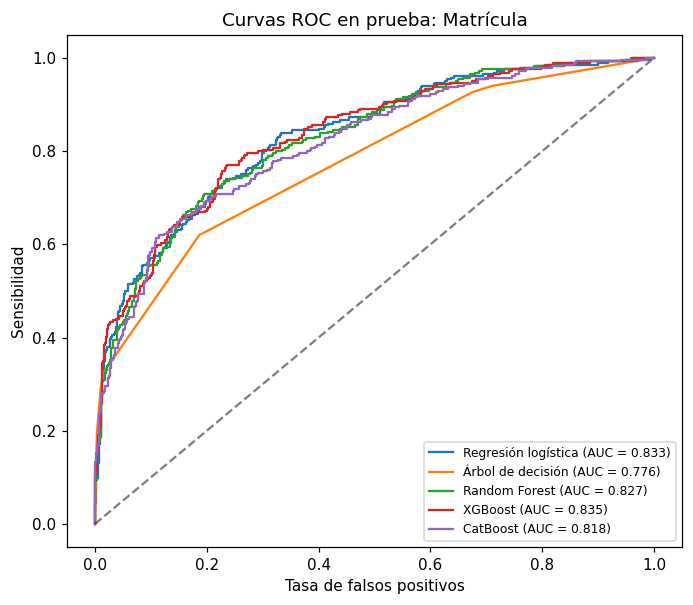

Figura guardada: resultados_tfm/figuras/fig_pr_at_enrollment.png


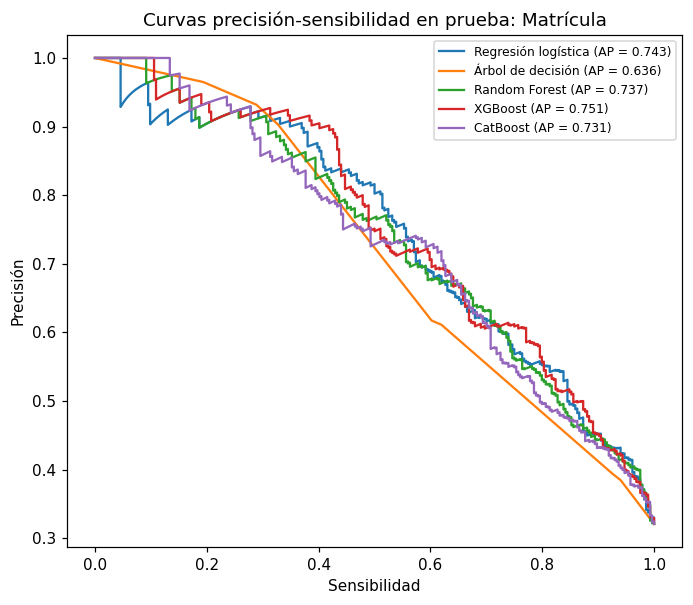


=== Primer semestre | Enrolled+Graduate | entrenamiento=3539 prueba=885 ===
  Regresión logística: CV G-Mean=0.8252 ± 0.0197 | prueba G-Mean=0.8505 | umbral=0.485 | 1.0 min
  Árbol de decisión: CV G-Mean=0.7922 ± 0.0209 | prueba G-Mean=0.7896 | umbral=0.430 | 0.5 min
  Random Forest: CV G-Mean=0.8138 ± 0.0214 | prueba G-Mean=0.8263 | umbral=0.470 | 12.3 min
  XGBoost: CV G-Mean=0.8250 ± 0.0161 | prueba G-Mean=0.8381 | umbral=0.460 | 5.0 min
  CatBoost: CV G-Mean=0.8256 ± 0.0108 | prueba G-Mean=0.8191 | umbral=0.455 | 24.2 min
Figura guardada: resultados_tfm/figuras/fig_roc_after_first_semester.png


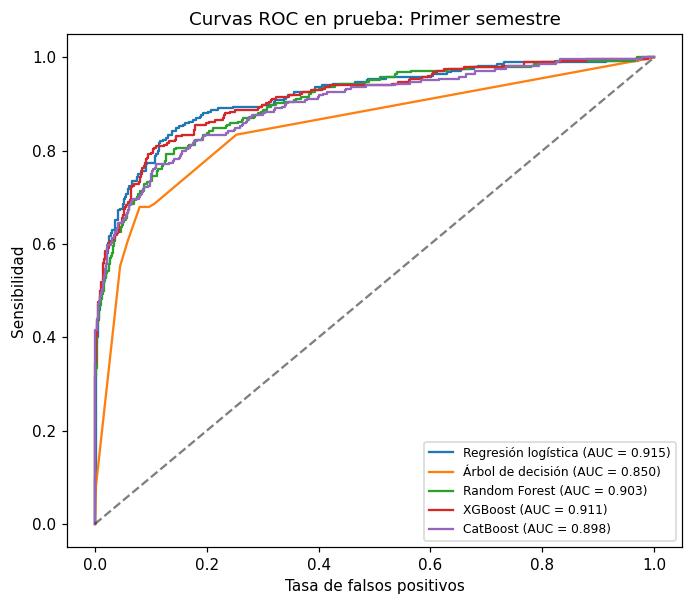

Figura guardada: resultados_tfm/figuras/fig_pr_after_first_semester.png


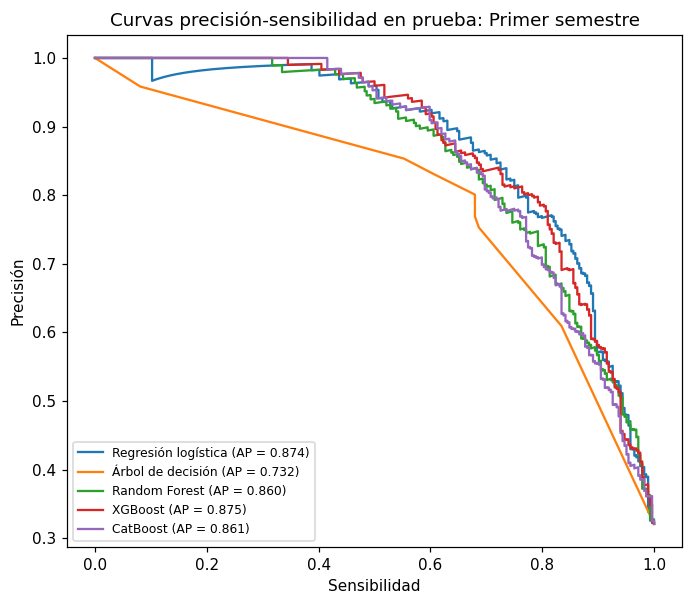

Figura guardada: resultados_tfm/figuras/fig_matriz_confusion_regresion_logistica.png


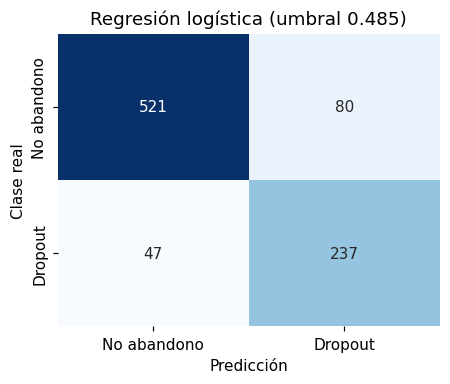

Figura guardada: resultados_tfm/figuras/fig_matriz_confusion_arbol_de_decision.png


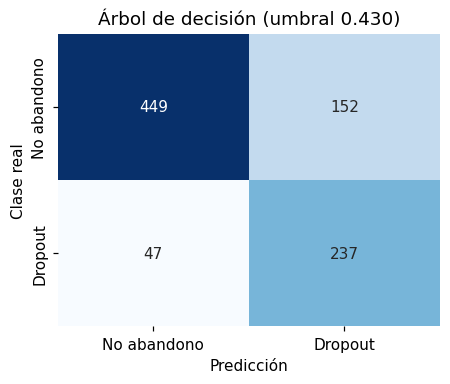

Figura guardada: resultados_tfm/figuras/fig_matriz_confusion_random_forest.png


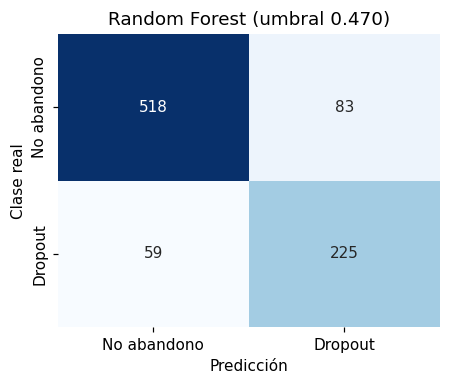

Figura guardada: resultados_tfm/figuras/fig_matriz_confusion_xgboost.png


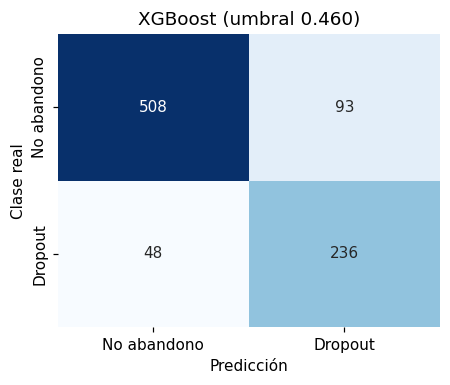

Figura guardada: resultados_tfm/figuras/fig_matriz_confusion_catboost.png


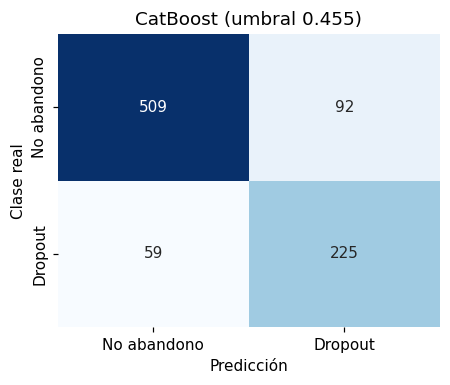


=== Segundo semestre | Enrolled+Graduate | entrenamiento=3539 prueba=885 ===
  Regresión logística: CV G-Mean=0.8415 ± 0.0259 | prueba G-Mean=0.8749 | umbral=0.465 | 0.9 min
  Árbol de decisión: CV G-Mean=0.8145 ± 0.0207 | prueba G-Mean=0.8479 | umbral=0.480 | 0.5 min
  Random Forest: CV G-Mean=0.8391 ± 0.0199 | prueba G-Mean=0.8580 | umbral=0.500 | 13.1 min
  XGBoost: CV G-Mean=0.8380 ± 0.0191 | prueba G-Mean=0.8663 | umbral=0.450 | 5.2 min
  CatBoost: CV G-Mean=0.8428 ± 0.0204 | prueba G-Mean=0.8627 | umbral=0.460 | 25.6 min
Figura guardada: resultados_tfm/figuras/fig_roc_after_second_semester.png


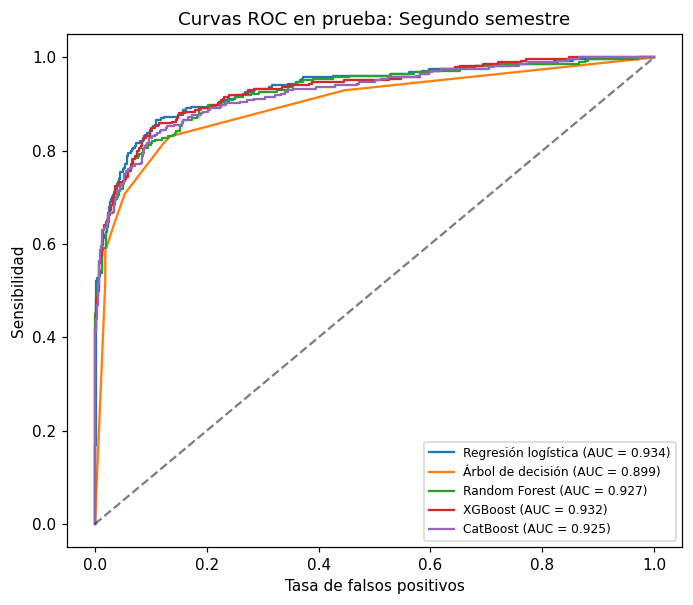

Figura guardada: resultados_tfm/figuras/fig_pr_after_second_semester.png


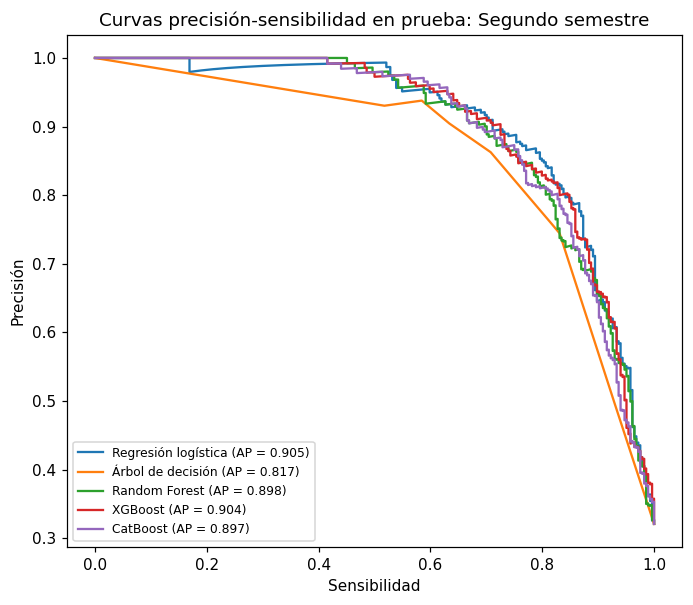


Tiempo total: 129.0 min


,Escenario,Población,Modelo,CV G-Mean media,CV G-Mean DE,CV Recall media,CV Recall DE,CV Specificity media,CV Specificity DE,CV Precision media,CV Precision DE,CV F1 media,CV F1 DE,CV ROC-AUC media,CV ROC-AUC DE,CV Accuracy media,CV Accuracy DE
0,at_enrollment,Enrolled+Graduate,Regresión logística,0.7340,0.0195,0.7010,0.0374,0.7698,0.0359,0.5924,0.0371,0.6411,0.0252,0.8179,0.0230,0.7477,0.0220
1,at_enrollment,Enrolled+Graduate,Árbol de decisión,0.6897,0.0271,0.6297,0.0560,0.7594,0.0618,0.5592,0.0546,0.5895,0.0336,0.7642,0.0230,0.7177,0.0349
2,at_enrollment,Enrolled+Graduate,Random Forest,0.7263,0.0230,0.7194,0.0408,0.7344,0.0350,0.5632,0.0339,0.6310,0.0283,0.8160,0.0205,0.7296,0.0237
3,at_enrollment,Enrolled+Graduate,XGBoost,0.7300,0.0197,0.7212,0.0435,0.7402,0.0301,0.5688,0.0245,0.6353,0.0232,0.8195,0.0209,0.7341,0.0183
4,at_enrollment,Enrolled+Graduate,CatBoost,0.7320,0.0209,0.7659,0.0422,0.7019,0.0540,0.5523,0.0418,0.6401,0.0247,0.8152,0.0199,0.7225,0.0298
5,after_first_semester,Enrolled+Graduate,Regresión logística,0.8252,0.0197,0.7907,0.0409,0.8626,0.0371,0.7351,0.0482,0.7603,0.0267,0.9017,0.0121,0.8395,0.0217
6,after_first_semester,Enrolled+Graduate,Árbol de decisión,0.7922,0.0209,0.7450,0.0375,0.8434,0.0344,0.6953,0.0433,0.7181,0.0273,0.8578,0.0153,0.8118,0.0222
7,after_first_semester,Enrolled+Graduate,Random Forest,0.8138,0.0214,0.7767,0.0362,0.8539,0.0383,0.7194,0.0526,0.7455,0.0297,0.8894,0.0141,0.8291,0.0246
8,after_first_semester,Enrolled+Graduate,XGBoost,0.8250,0.0161,0.8066,0.0375,0.8451,0.0361,0.7147,0.0452,0.7564,0.0223,0.9000,0.0132,0.8327,0.0195
9,after_first_semester,Enrolled+Graduate,CatBoost,0.8256,0.0108,0.7898,0.0350,0.8642,0.0347,0.7374,0.0452,0.7610,0.0153,0.8982,0.0114,0.8403,0.0159


,Escenario,Población,Modelo,Umbral,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,G-Mean,ROC-AUC,Average precision,TN,FP,FN,TP
0,at_enrollment,Enrolled+Graduate,Regresión logística,0.485,0.7559,0.7497,0.5977,0.7324,0.7671,0.6582,0.7495,0.8330,0.7426,461,140,76,208
1,at_enrollment,Enrolled+Graduate,Árbol de decisión,0.500,0.7514,0.7167,0.6111,0.6197,0.8136,0.6154,0.7101,0.7761,0.6360,489,112,108,176
2,at_enrollment,Enrolled+Graduate,Random Forest,0.455,0.7480,0.7467,0.5845,0.7430,0.7504,0.6543,0.7467,0.8272,0.7373,451,150,73,211
3,at_enrollment,Enrolled+Graduate,XGBoost,0.425,0.7288,0.7483,0.5534,0.8028,0.6938,0.6552,0.7463,0.8346,0.7507,417,184,56,228
4,at_enrollment,Enrolled+Graduate,CatBoost,0.410,0.7345,0.7321,0.5675,0.7254,0.7388,0.6368,0.7320,0.8181,0.7309,444,157,78,206
5,after_first_semester,Enrolled+Graduate,Regresión logística,0.485,0.8565,0.8507,0.7476,0.8345,0.8669,0.7887,0.8505,0.9145,0.8745,521,80,47,237
6,after_first_semester,Enrolled+Graduate,Árbol de decisión,0.430,0.7751,0.7908,0.6093,0.8345,0.7471,0.7043,0.7896,0.8501,0.7318,449,152,47,237
7,after_first_semester,Enrolled+Graduate,Random Forest,0.470,0.8395,0.8271,0.7305,0.7923,0.8619,0.7601,0.8263,0.9033,0.8603,518,83,59,225
8,after_first_semester,Enrolled+Graduate,XGBoost,0.460,0.8407,0.8381,0.7173,0.8310,0.8453,0.7700,0.8381,0.9111,0.8749,508,93,48,236
9,after_first_semester,Enrolled+Graduate,CatBoost,0.455,0.8294,0.8196,0.7098,0.7923,0.8469,0.7488,0.8191,0.8978,0.8608,509,92,59,225


In [ ]:
t_start = time.perf_counter()
results_by_scenario = {s: run_scenario(df_original, s) for s in SCENARIOS}
print(f"\nTiempo total: {(time.perf_counter() - t_start) / 60:.1f} min")

cv_all = pd.concat([r["cv"] for r in results_by_scenario.values()], ignore_index=True)
test_all = pd.concat([r["test"] for r in results_by_scenario.values()], ignore_index=True)
params_all = pd.concat([r["params"] for r in results_by_scenario.values()], ignore_index=True)
folds_all = pd.concat([r["folds"] for r in results_by_scenario.values()], ignore_index=True)
display(cv_all.round(4)); display(test_all.round(4))

## 9. Análisis de sensibilidad: exclusión de `Enrolled`

Se repite el escenario principal (primer semestre) sin los registros `Enrolled`. La población cambia, por lo que estos resultados no se comparan directamente con los del análisis principal.


=== Primer semestre | Sin Enrolled | entrenamiento=2904 prueba=726 ===
  Regresión logística: CV G-Mean=0.8733 ± 0.0236 | prueba G-Mean=0.8720 | umbral=0.410 | 0.6 min
  Árbol de decisión: CV G-Mean=0.8419 ± 0.0210 | prueba G-Mean=0.8503 | umbral=0.305 | 0.4 min
  Random Forest: CV G-Mean=0.8624 ± 0.0245 | prueba G-Mean=0.8823 | umbral=0.510 | 10.4 min
  XGBoost: CV G-Mean=0.8719 ± 0.0240 | prueba G-Mean=0.8974 | umbral=0.500 | 3.8 min
  CatBoost: CV G-Mean=0.8701 ± 0.0225 | prueba G-Mean=0.8814 | umbral=0.345 | 20.9 min
Figura guardada: resultados_tfm/figuras/fig_roc_after_first_semester_sin_enrolled.png


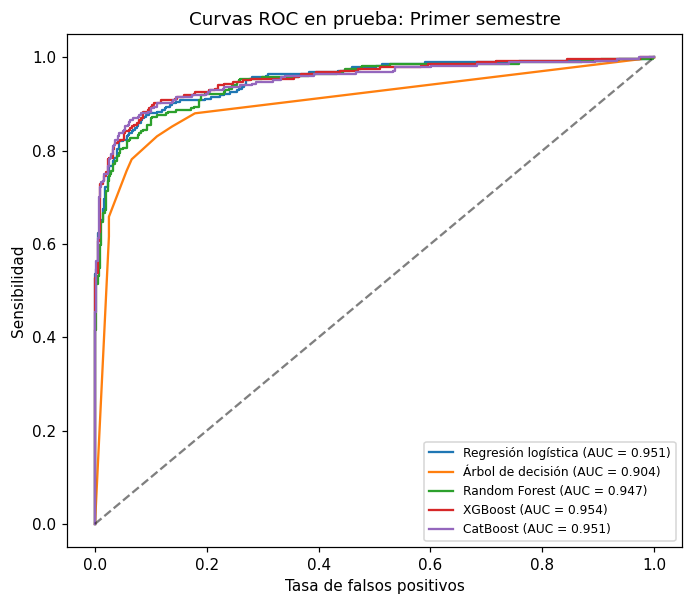

Figura guardada: resultados_tfm/figuras/fig_pr_after_first_semester_sin_enrolled.png


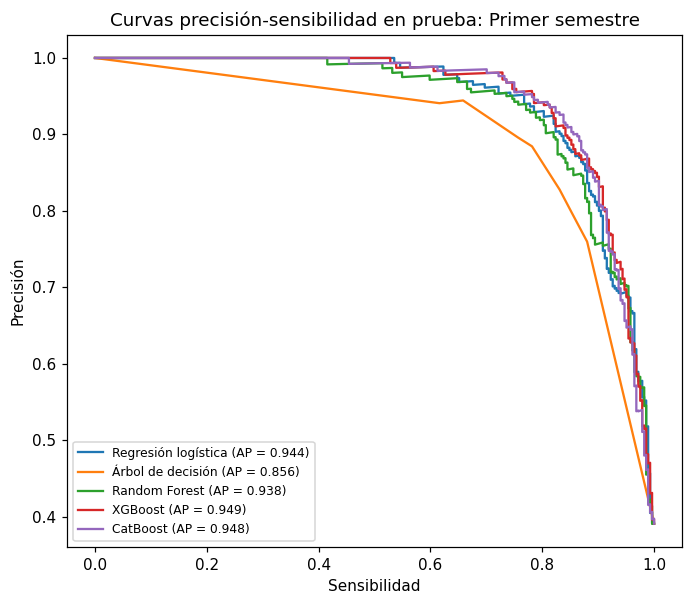

,Escenario,Población,Modelo,CV G-Mean media,CV G-Mean DE,CV Recall media,CV Recall DE,CV Specificity media,CV Specificity DE,CV Precision media,CV Precision DE,CV F1 media,CV F1 DE,CV ROC-AUC media,CV ROC-AUC DE,CV Accuracy media,CV Accuracy DE
0,after_first_semester,Sin Enrolled,Regresión logística,0.8733,0.0236,0.8435,0.0272,0.9050,0.0424,0.8544,0.0573,0.8478,0.0309,0.9330,0.0118,0.8809,0.0269
1,after_first_semester,Sin Enrolled,Árbol de decisión,0.8419,0.0210,0.7994,0.0395,0.8879,0.0392,0.8243,0.0463,0.8103,0.0254,0.8927,0.0234,0.8533,0.0221
2,after_first_semester,Sin Enrolled,Random Forest,0.8624,0.0245,0.8197,0.0360,0.9077,0.0237,0.8519,0.0349,0.8351,0.0297,0.9286,0.0150,0.8733,0.0227
3,after_first_semester,Sin Enrolled,XGBoost,0.8719,0.0240,0.8391,0.0410,0.9066,0.0238,0.8535,0.0337,0.8456,0.0285,0.9332,0.0124,0.8802,0.0214
4,after_first_semester,Sin Enrolled,CatBoost,0.8701,0.0225,0.8453,0.0388,0.8964,0.0276,0.8414,0.0370,0.8426,0.0267,0.9324,0.0147,0.8764,0.0211


,Escenario,Población,Modelo,Umbral,Accuracy,Balanced accuracy,Precision,Recall,Specificity,F1,G-Mean,ROC-AUC,Average precision,TN,FP,FN,TP
0,after_first_semester,Sin Enrolled,Regresión logística,0.410,0.8650,0.8728,0.7818,0.9085,0.8371,0.8404,0.8720,0.9514,0.9444,370,72,26,258
1,after_first_semester,Sin Enrolled,Árbol de decisión,0.305,0.8444,0.8508,0.7599,0.8803,0.8213,0.8157,0.8503,0.9038,0.8557,363,79,34,250
2,after_first_semester,Sin Enrolled,Random Forest,0.510,0.8843,0.8823,0.8378,0.8732,0.8914,0.8552,0.8823,0.9469,0.9381,394,48,36,248
3,after_first_semester,Sin Enrolled,XGBoost,0.500,0.8981,0.8974,0.8523,0.8944,0.9005,0.8729,0.8974,0.9542,0.9489,398,44,30,254
4,after_first_semester,Sin Enrolled,CatBoost,0.345,0.8760,0.8818,0.8012,0.9085,0.8552,0.8515,0.8814,0.9512,0.9477,378,64,26,258


In [ ]:
sensitivity_results = None
if RUN_SENSITIVITY_EXCLUDING_ENROLLED:
    sensitivity_results = run_scenario(df_original, SENSITIVITY_SCENARIO, exclude_enrolled=True)
    display(sensitivity_results["cv"].round(4)); display(sensitivity_results["test"].round(4))

## 10. Tablas

Se exportan a `resultados_tfm/tablas/` en CSV y Markdown: comparación en prueba, matrices de confusión, validación cruzada, comparación temporal de los cinco modelos, hiperparámetros (espacio, presupuesto, valores finales) y umbrales.

Modelo seleccionado por el criterio a priori (máximo G-Mean medio en CV anidada): CatBoost


,Modelo,Umbral,Accuracy,Precision,Recall,Specificity,F1,ROC-AUC,G-Mean
0,Regresión logística,0.485,0.8565,0.7476,0.8345,0.8669,0.7887,0.9145,0.8505
1,Árbol de decisión,0.430,0.7751,0.6093,0.8345,0.7471,0.7043,0.8501,0.7896
2,Random Forest,0.470,0.8395,0.7305,0.7923,0.8619,0.7601,0.9033,0.8263
3,XGBoost,0.460,0.8407,0.7173,0.8310,0.8453,0.7700,0.9111,0.8381
4,CatBoost,0.455,0.8294,0.7098,0.7923,0.8469,0.7488,0.8978,0.8191


,Modelo,TN,FP,FN,TP
0,Regresión logística,521,80,47,237
1,Árbol de decisión,449,152,47,237
2,Random Forest,518,83,59,225
3,XGBoost,508,93,48,236
4,CatBoost,509,92,59,225


,Modelo,CV G-Mean media,CV G-Mean DE,CV Recall media,CV Specificity media,CV ROC-AUC media
4,CatBoost,0.8256,0.0108,0.7898,0.8642,0.8982
0,Regresión logística,0.8252,0.0197,0.7907,0.8626,0.9017
3,XGBoost,0.8250,0.0161,0.8066,0.8451,0.9000
2,Random Forest,0.8138,0.0214,0.7767,0.8539,0.8894
1,Árbol de decisión,0.7922,0.0209,0.7450,0.8434,0.8578


,Modelo,Espacio de búsqueda,Combinaciones posibles,Configuraciones evaluadas,Pliegues internos,Métrica optimizada,Balanceo,Hiperparámetros finales
0,Regresión logística,"{""model__C"": [0.001, 0.01, 0.1, 1.0, 10.0, 100...",12,10,3,"G-Mean (umbral 0,5)",oversampling,"{""model__penalty"": ""l2"", ""model__class_weight""..."
1,Árbol de decisión,"{""model__max_depth"": [3, 4, 5, 6, 8, 10, 12, n...",80,10,3,"G-Mean (umbral 0,5)",oversampling,"{""model__min_samples_leaf"": 40, ""model__max_de..."
2,Random Forest,"{""model__n_estimators"": [200, 400], ""model__ma...",64,10,3,"G-Mean (umbral 0,5)",oversampling,"{""model__n_estimators"": 200, ""model__min_sampl..."
3,XGBoost,"{""model__n_estimators"": [200, 400, 600], ""mode...",3888,10,3,"G-Mean (umbral 0,5)",oversampling,"{""model__subsample"": 0.7, ""model__scale_pos_we..."
4,CatBoost,"{""model__iterations"": [300, 500], ""model__dept...",48,10,3,"G-Mean (umbral 0,5)",oversampling,"{""model__learning_rate"": 0.05, ""model__l2_leaf..."


,Modelo,Umbral final,G-Mean OOF en el umbral,Sensibilidad OOF en el umbral,Precisión OOF en el umbral
0,Regresión logística,0.485,0.8286,0.7951,0.7338
1,Árbol de decisión,0.430,0.7946,0.7916,0.6494
2,Random Forest,0.470,0.8213,0.7845,0.7258
3,XGBoost,0.460,0.8296,0.8047,0.7245
4,CatBoost,0.455,0.8285,0.7863,0.7456


,Modelo,mean,std,min,max
0,Regresión logística,0.4865,0.0426,0.420,0.55
1,Árbol de decisión,0.4880,0.0477,0.425,0.56
2,Random Forest,0.4595,0.0241,0.425,0.49
3,XGBoost,0.4490,0.0327,0.395,0.51
4,CatBoost,0.4675,0.0310,0.425,0.52


,Momento,Modelo,CV G-Mean media,CV G-Mean DE,G-Mean prueba,Sensibilidad prueba,ROC-AUC prueba
0,Matrícula,Regresión logística,0.7340,0.0195,0.7495,0.7324,0.8330
1,Matrícula,Árbol de decisión,0.6897,0.0271,0.7101,0.6197,0.7761
2,Matrícula,Random Forest,0.7263,0.0230,0.7467,0.7430,0.8272
3,Matrícula,XGBoost,0.7300,0.0197,0.7463,0.8028,0.8346
4,Matrícula,CatBoost,0.7320,0.0209,0.7320,0.7254,0.8181
5,Primer semestre,Regresión logística,0.8252,0.0197,0.8505,0.8345,0.9145
6,Primer semestre,Árbol de decisión,0.7922,0.0209,0.7896,0.8345,0.8501
7,Primer semestre,Random Forest,0.8138,0.0214,0.8263,0.7923,0.9033
8,Primer semestre,XGBoost,0.8250,0.0161,0.8381,0.8310,0.9111
9,Primer semestre,CatBoost,0.8256,0.0108,0.8191,0.7923,0.8978


Figura guardada: resultados_tfm/figuras/fig_comparacion_temporal.png


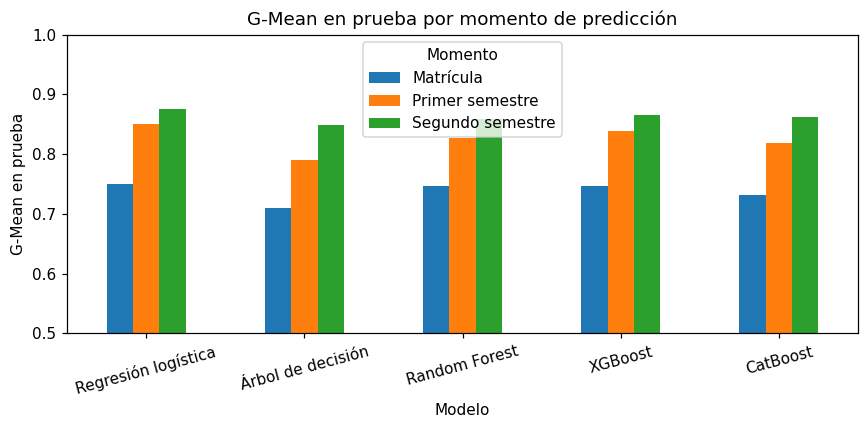

,Modelo,Umbral,Recall,Specificity,Precision,ROC-AUC,G-Mean,CV G-Mean media,CV G-Mean DE
0,Regresión logística,0.410,0.9085,0.8371,0.7818,0.9514,0.8720,0.8733,0.0236
1,Árbol de decisión,0.305,0.8803,0.8213,0.7599,0.9038,0.8503,0.8419,0.0210
2,Random Forest,0.510,0.8732,0.8914,0.8378,0.9469,0.8823,0.8624,0.0245
3,XGBoost,0.500,0.8944,0.9005,0.8523,0.9542,0.8974,0.8719,0.0240
4,CatBoost,0.345,0.9085,0.8552,0.8012,0.9512,0.8814,0.8701,0.0225


In [ ]:
main = results_by_scenario[MAIN_SCENARIO]
order_key = lambda d: d.set_index("Modelo").loc[MODEL_ORDER].reset_index()

tabla_prueba = order_key(main["test"])[["Modelo", "Umbral", "Accuracy", "Precision", "Recall", "Specificity", "F1", "ROC-AUC", "G-Mean"]]
tabla_confusion = order_key(main["test"])[["Modelo", "TN", "FP", "FN", "TP"]]
tabla_cv = order_key(main["cv"])[["Modelo", "CV G-Mean media", "CV G-Mean DE", "CV Recall media", "CV Specificity media", "CV ROC-AUC media"]]
tabla_cv = tabla_cv.sort_values("CV G-Mean media", ascending=False)
tabla_hiper = order_key(main["params"])[["Modelo", "Espacio de búsqueda", "Combinaciones posibles", "Configuraciones evaluadas",
                                          "Pliegues internos", "Métrica optimizada", "Balanceo", "Hiperparámetros finales"]]
tabla_umbral = order_key(main["params"])[["Modelo", "Umbral final", "G-Mean OOF en el umbral", "Sensibilidad OOF en el umbral", "Precisión OOF en el umbral"]]
# Umbrales elegidos en cada pliegue externo: muestra la estabilidad de la regla de decisión.
tabla_umbral_pliegues = (folds_all[folds_all["Escenario"] == MAIN_SCENARIO].groupby("Modelo")["Umbral"]
                         .agg(["mean", "std", "min", "max"]).reindex(MODEL_ORDER).reset_index())

selected_model = tabla_cv.iloc[0]["Modelo"]
print("Modelo seleccionado por el criterio a priori (máximo G-Mean medio en CV anidada):", selected_model)
for name, df_ in [("tabla_prueba_primer_semestre", tabla_prueba), ("tabla_confusion_primer_semestre", tabla_confusion),
                  ("tabla_cv_anidada_primer_semestre", tabla_cv), ("tabla_hiperparametros", tabla_hiper),
                  ("tabla_umbrales", tabla_umbral), ("tabla_umbrales_pliegues", tabla_umbral_pliegues)]:
    display(df_.round(4)); save_table(df_, name)

# Comparación temporal con los cinco modelos.
if RUN_ALL_SCENARIOS:
    temporal = test_all.merge(cv_all[["Escenario", "Modelo", "CV G-Mean media", "CV G-Mean DE"]], on=["Escenario", "Modelo"])
    temporal["Momento"] = temporal["Escenario"].map(SCENARIO_LABELS)
    tabla_temporal = temporal[["Momento", "Modelo", "CV G-Mean media", "CV G-Mean DE", "G-Mean", "Recall", "ROC-AUC"]]
    tabla_temporal = tabla_temporal.rename(columns={"G-Mean": "G-Mean prueba", "Recall": "Sensibilidad prueba", "ROC-AUC": "ROC-AUC prueba"})
    display(tabla_temporal.round(4)); save_table(tabla_temporal, "tabla_comparacion_temporal")
    piv = temporal.pivot(index="Modelo", columns="Momento", values="G-Mean").reindex(MODEL_ORDER)[["Matrícula", "Primer semestre", "Segundo semestre"]]
    piv.plot(kind="bar", rot=15, figsize=(8, 4))
    plt.ylabel("G-Mean en prueba"); plt.ylim(0.5, 1.0); plt.title("G-Mean en prueba por momento de predicción")
    plt.legend(title="Momento"); plt.tight_layout(); save_fig("fig_comparacion_temporal"); plt.show(); plt.close("all")

if sensitivity_results is not None:
    sens = order_key(sensitivity_results["test"])[["Modelo", "Umbral", "Recall", "Specificity", "Precision", "ROC-AUC", "G-Mean"]]
    sens = sens.merge(sensitivity_results["cv"][["Modelo", "CV G-Mean media", "CV G-Mean DE"]], on="Modelo")
    display(sens.round(4)); save_table(sens, "tabla_sensibilidad_sin_enrolled")

## 11. Pruebas estadísticas

- **Friedman** sobre el G-Mean de los 10 pliegues externos (H0: los cinco modelos tienen el mismo rango medio) y **Nemenyi** para los 10 pares; el valor p de Nemenyi ya controla el error de familia, por lo que no se ajusta de nuevo.
- **McNemar exacto** sobre las predicciones de prueba (H0: ambos clasificadores cometen la misma proporción de errores discordantes).
- **DeLong** sobre las probabilidades de prueba (H0: igual ROC-AUC).
- McNemar y DeLong: corrección de **Holm** dentro de cada familia de 10 comparaciones.
- **Bootstrap** (1000 remuestreos) para intervalos de confianza al 95 % de las métricas de prueba.

Los pliegues no son independientes (comparten observaciones de entrenamiento), por lo que Friedman y Nemenyi se interpretan como evidencia exploratoria.

In [ ]:
def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float); out = np.full(p.shape, np.nan)
    valid = np.where(np.isfinite(p))[0]
    if len(valid) == 0: return out
    order = valid[np.argsort(p[valid])]; m = len(order)
    adj = np.minimum(np.maximum.accumulate([(m - r) * p[i] for r, i in enumerate(order)]), 1.0)
    out[order] = adj
    return out

def compute_midrank(x):
    J = np.argsort(x); Z = x[J]; N = len(x); T = np.zeros(N); i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]: j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1; i = j
    T2 = np.empty(N); T2[J] = T
    return T2

def delong_test(y_true, p1, p2):
    y_true = np.asarray(y_true).astype(int); order = np.argsort(-y_true)
    preds = np.vstack([p1, p2])[:, order]; m = int(y_true.sum()); n = preds.shape[1] - m
    tx = np.array([compute_midrank(r[:m]) for r in preds]); ty = np.array([compute_midrank(r[m:]) for r in preds])
    tz = np.array([compute_midrank(r) for r in preds])
    aucs = tz[:, :m].sum(axis=1) / (m * n) - (m + 1) / (2 * n)
    v01 = (tz[:, :m] - tx) / n; v10 = 1 - (tz[:, m:] - ty) / m
    cov = np.cov(v01) / m + np.cov(v10) / n
    var = cov[0, 0] + cov[1, 1] - 2 * cov[0, 1]
    z = (aucs[0] - aucs[1]) / np.sqrt(var) if var > 0 else np.nan
    return aucs[0] - aucs[1], z, (2 * norm.sf(abs(z)) if np.isfinite(z) else np.nan)

def bootstrap_ci(y_true, y_pred, y_prob, n_boot=N_BOOT, seed=SEED):
    rng = np.random.default_rng(seed); y_true, y_pred, y_prob = map(np.asarray, (y_true, y_pred, y_prob))
    keys = ["Precision", "Recall", "Specificity", "F1", "G-Mean", "ROC-AUC"]; vals = {k: [] for k in keys}
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2: continue
        m = metric_dict(y_true[idx], y_pred[idx], y_prob[idx])
        for k in keys: vals[k].append(m[k])
    return {k: (np.quantile(v, .025), np.quantile(v, .975)) for k, v in vals.items()}

friedman_rows, pair_rows, ci_rows = [], [], []
for scenario, res in results_by_scenario.items():
    preds = res["predictions"]; names = [n for n in MODEL_ORDER if n in preds]
    ytest = np.asarray(res["y_test"])
    # Friedman + Nemenyi sobre pliegues externos
    fold_arr = np.array([preds[n]["nested"]["G-Mean"].to_numpy() for n in names])   # modelos x pliegues
    fr = friedmanchisquare(*fold_arr)
    ranks = np.vstack([rankdata(-fold_arr[:, j]) for j in range(fold_arr.shape[1])]).mean(axis=0)
    k, N = fold_arr.shape
    friedman_rows.append({"Escenario": SCENARIO_LABELS[scenario], "χ² de Friedman": fr.statistic, "p": fr.pvalue,
                          **{f"Rango medio {n}": r for n, r in zip(names, ranks)}})
    denom = np.sqrt(k * (k + 1) / (6.0 * N))
    rows = []
    for i, j in itertools.combinations(range(k), 2):
        a, b = names[i], names[j]
        q = abs(ranks[i] - ranks[j]) / denom
        p_nem = float(studentized_range.sf(q * np.sqrt(2), k, np.inf))
        pa, pb = preds[a]["pred"], preds[b]["pred"]
        table = np.array([[np.sum((pa == ytest) & (pb == ytest)), np.sum((pa == ytest) & (pb != ytest))],
                          [np.sum((pa != ytest) & (pb == ytest)), np.sum((pa != ytest) & (pb != ytest))]])
        p_mc = mcnemar(table, exact=True).pvalue
        d_auc, z, p_dl = delong_test(ytest, preds[a]["prob"], preds[b]["prob"])
        rows.append({"Escenario": SCENARIO_LABELS[scenario], "Modelo A": a, "Modelo B": b,
                     "Dif. rango medio (negativo = A mejor)": ranks[i] - ranks[j], "p Nemenyi": p_nem,
                     "Discordantes A acierta/B falla": int(table[0, 1]), "Discordantes A falla/B acierta": int(table[1, 0]),
                     "p McNemar": p_mc, "Dif. ROC-AUC (A − B)": d_auc, "z DeLong": z, "p DeLong": p_dl})
    for col in ["p McNemar", "p DeLong"]:
        adj = holm_adjust([r[col] for r in rows])
        for r, v in zip(rows, adj): r[f"{col} (Holm)"] = v
    pair_rows += rows
    for n in names:
        ci = bootstrap_ci(ytest, preds[n]["pred"], preds[n]["prob"])
        ci_rows.append({"Escenario": SCENARIO_LABELS[scenario], "Modelo": n,
                        **{f"{m_} IC95": f"[{lo:.3f}; {hi:.3f}]" for m_, (lo, hi) in ci.items()}})

friedman_all = pd.DataFrame(friedman_rows); pairwise_all = pd.DataFrame(pair_rows); ci_all = pd.DataFrame(ci_rows)
display(friedman_all.round(4)); display(pairwise_all.round(4)); display(ci_all)
save_table(friedman_all, "tabla_friedman"); save_table(pairwise_all, "tabla_comparaciones_pares")
save_table(ci_all, "tabla_ic_bootstrap")
save_table(pairwise_all[pairwise_all["Escenario"] == SCENARIO_LABELS[MAIN_SCENARIO]], "tabla_comparaciones_pares_primer_semestre")

,Escenario,χ² de Friedman,p,Rango medio Regresión logística,Rango medio Árbol de decisión,Rango medio Random Forest,Rango medio XGBoost,Rango medio CatBoost
0,Matrícula,18.2714,0.0011,2.40,4.9,2.65,2.55,2.5
1,Primer semestre,19.3600,0.0007,2.50,4.7,3.50,2.10,2.2
2,Segundo semestre,15.3367,0.0041,2.65,4.7,2.65,2.80,2.2


,Escenario,Modelo A,Modelo B,Dif. rango medio (negativo = A mejor),p Nemenyi,Discordantes A acierta/B falla,Discordantes A falla/B acierta,p McNemar,Dif. ROC-AUC (A − B),z DeLong,p DeLong,p McNemar (Holm),p DeLong (Holm)
0,Matrícula,Regresión logística,Árbol de decisión,-2.50,0.0037,85,81,0.8160,0.0568,4.5676,0.0000,1.0000,0.0000
1,Matrícula,Regresión logística,Random Forest,-0.25,0.9967,66,59,0.5917,0.0058,0.7571,0.4490,1.0000,0.8980
2,Matrícula,Regresión logística,XGBoost,-0.15,0.9996,56,32,0.0138,-0.0016,-0.2835,0.7768,0.1375,0.8980
3,Matrícula,Regresión logística,CatBoost,-0.10,0.9999,72,53,0.1070,0.0149,1.8354,0.0664,0.8563,0.3322
4,Matrícula,Árbol de decisión,Random Forest,2.25,0.0127,54,51,0.8454,-0.0510,-5.4301,0.0000,1.0000,0.0000
5,Matrícula,Árbol de decisión,XGBoost,2.35,0.0079,82,62,0.1130,-0.0584,-6.0431,0.0000,0.8563,0.0000
6,Matrícula,Árbol de decisión,CatBoost,2.40,0.0062,90,75,0.2757,-0.0420,-3.5771,0.0003,1.0000,0.0024
7,Matrícula,Random Forest,XGBoost,0.10,0.9999,50,33,0.0784,-0.0074,-1.6150,0.1063,0.7058,0.4253
8,Matrícula,Random Forest,CatBoost,0.15,0.9996,67,55,0.3193,0.0091,1.0852,0.2778,1.0000,0.8335
9,Matrícula,XGBoost,CatBoost,0.05,1.0000,63,68,0.7269,0.0165,2.2452,0.0248,1.0000,0.1485


,Escenario,Modelo,Precision IC95,Recall IC95,Specificity IC95,F1 IC95,G-Mean IC95,ROC-AUC IC95
0,Matrícula,Regresión logística,[0.550; 0.651],[0.680; 0.782],[0.734; 0.802],[0.615; 0.699],[0.718; 0.778],[0.803; 0.860]
1,Matrícula,Árbol de decisión,[0.552; 0.665],[0.561; 0.673],[0.783; 0.843],[0.567; 0.656],[0.675; 0.742],[0.743; 0.807]
2,Matrícula,Random Forest,[0.536; 0.634],[0.689; 0.792],[0.716; 0.785],[0.610; 0.696],[0.715; 0.778],[0.797; 0.855]
3,Matrícula,XGBoost,[0.505; 0.601],[0.756; 0.847],[0.658; 0.731],[0.612; 0.694],[0.717; 0.774],[0.805; 0.862]
4,Matrícula,CatBoost,[0.518; 0.617],[0.672; 0.778],[0.703; 0.774],[0.591; 0.679],[0.700; 0.764],[0.788; 0.847]
5,Primer semestre,Regresión logística,[0.698; 0.795],[0.789; 0.878],[0.838; 0.894],[0.750; 0.826],[0.823; 0.877],[0.890; 0.936]
6,Primer semestre,Árbol de decisión,[0.560; 0.660],[0.787; 0.876],[0.712; 0.782],[0.663; 0.743],[0.761; 0.817],[0.821; 0.878]
7,Primer semestre,Random Forest,[0.680; 0.780],[0.741; 0.837],[0.832; 0.891],[0.720; 0.797],[0.797; 0.854],[0.879; 0.925]
8,Primer semestre,XGBoost,[0.667; 0.772],[0.785; 0.875],[0.816; 0.876],[0.730; 0.809],[0.810; 0.867],[0.887; 0.932]
9,Primer semestre,CatBoost,[0.660; 0.763],[0.742; 0.840],[0.817; 0.877],[0.708; 0.788],[0.790; 0.848],[0.872; 0.921]


## 12. Interpretabilidad global con SHAP: XGBoost y regresión logística

- **XGBoost**: `TreeExplainer` con perturbación intervencional, fondo de 100 observaciones de entrenamiento y salida en **probabilidad** de `Dropout`.
- Si el modelo seleccionado por el criterio de validación no es ninguno de los dos, se explica también (TreeExplainer para árbol y Random Forest; SHAP nativo de CatBoost en log-odds).
- **Regresión logística**: `LinearExplainer` con el mismo fondo; salida en **log-odds**.
- Como cada variable nominal se reparte en varias columnas One-Hot, los valores SHAP se **suman por variable original** antes de ordenar la importancia. La suma conserva la propiedad aditiva de SHAP.
- Las dos escalas son distintas, así que la comparación entre modelos se hace con rankings y cuotas relativas de importancia, no con magnitudes absolutas.

XGBoost: error máximo de aditividad (probabilidad) = 4.68e-07
SHAP calculado también para el modelo seleccionado (CatBoost), escala: log-odds


,Variable,Tipo,Columnas One-Hot,|SHAP| medio XGBoost (prob.),|SHAP| medio RL (log-odds),Cuota XGBoost (%),Cuota RL (%),|SHAP| medio CatBoost (log-odds),Rango CatBoost,Rango XGBoost,Rango RL
22,Curricular units 1st sem (approved),Numérica/ordinal,1,0.1771,1.5718,29.8690,28.8774,1.0355,1,1,1
14,Tuition fees up to date,Categórica,2,0.0623,0.4121,10.5137,7.5718,0.5208,2,2,3
17,Age at enrollment,Numérica/ordinal,1,0.0486,0.2044,8.1898,3.7549,0.2490,5,3,8
23,Curricular units 1st sem (grade),Numérica/ordinal,1,0.0452,0.0821,7.6268,1.5081,0.2229,6,4,18
20,Curricular units 1st sem (enrolled),Numérica/ordinal,1,0.0379,0.5074,6.3894,9.3228,0.2602,4,5,2
3,Course,Categórica,17,0.0335,0.3355,5.6499,6.1635,0.2623,3,6,4
16,Scholarship holder,Categórica,2,0.0332,0.2309,5.6079,4.2422,0.1900,7,7,7
25,Unemployment rate,Numérica/ordinal,1,0.0278,0.2717,4.6977,4.9917,0.1648,8,8,5
13,Debtor,Categórica,2,0.0208,0.1516,3.5025,2.7849,0.1128,12,9,11
15,Gender,Categórica,2,0.0195,0.1438,3.2976,2.6416,0.0829,15,10,12


{
  "rho_spearman_rangos": 0.8364581986091109,
  "p_valor": 2.9534159608101966e-08,
  "coincidencias_top10": 7,
  "comunes_top10": [
    "Age at enrollment",
    "Course",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (enrolled)",
    "Scholarship holder",
    "Tuition fees up to date",
    "Unemployment rate"
  ],
  "solo_XGBoost_top10": [
    "Curricular units 1st sem (grade)",
    "Debtor",
    "Gender"
  ],
  "solo_RL_top10": [
    "Application mode",
    "Curricular units 1st sem (credited)",
    "Father's occupation"
  ]
}
Figura guardada: resultados_tfm/figuras/fig_shap_bar_xgboost_agregado.png


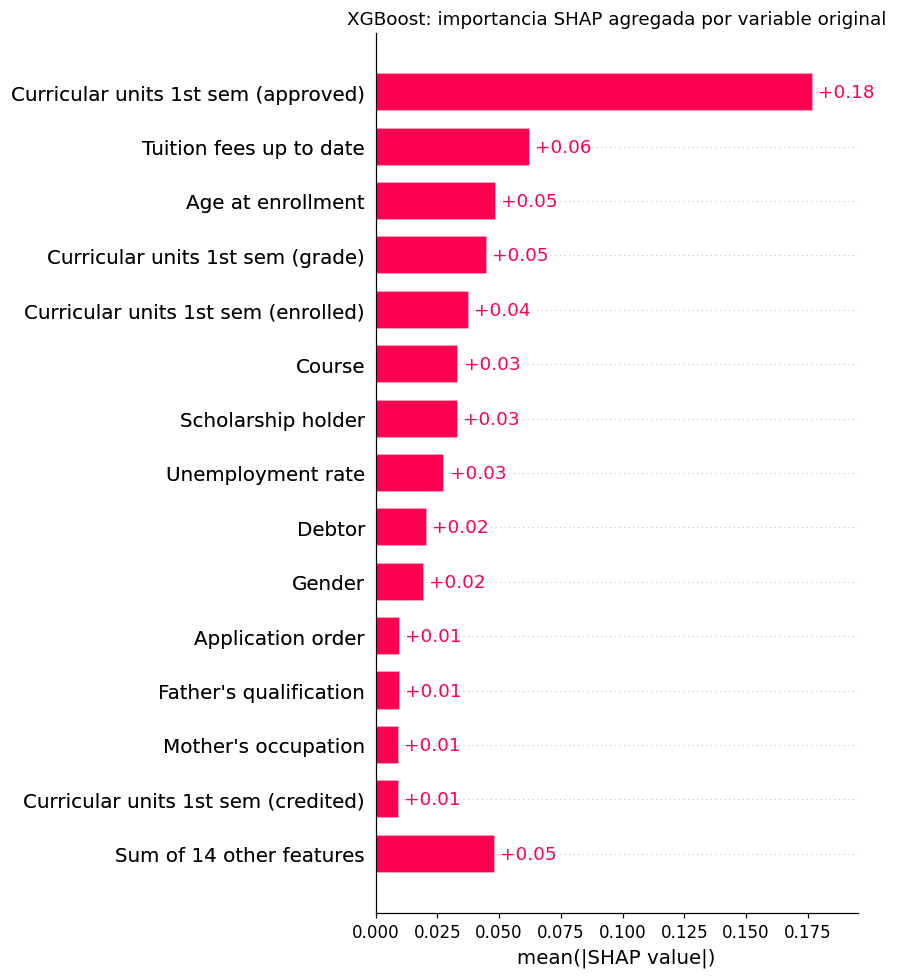

Figura guardada: resultados_tfm/figuras/fig_shap_beeswarm_xgboost.png


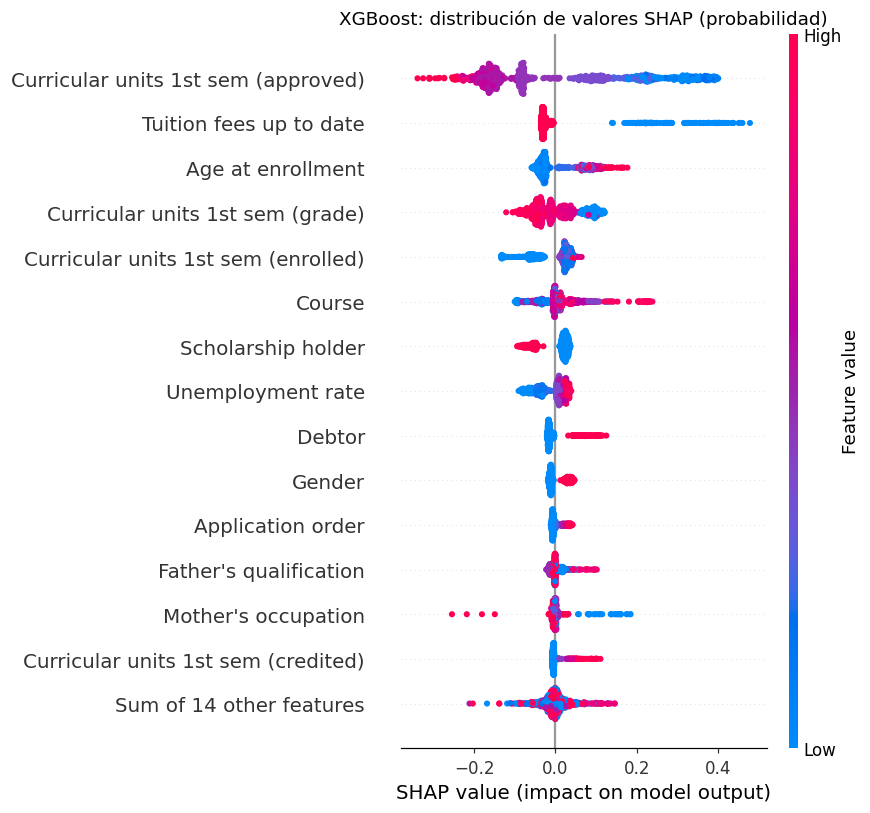

Figura guardada: resultados_tfm/figuras/fig_shap_bar_rl_agregado.png


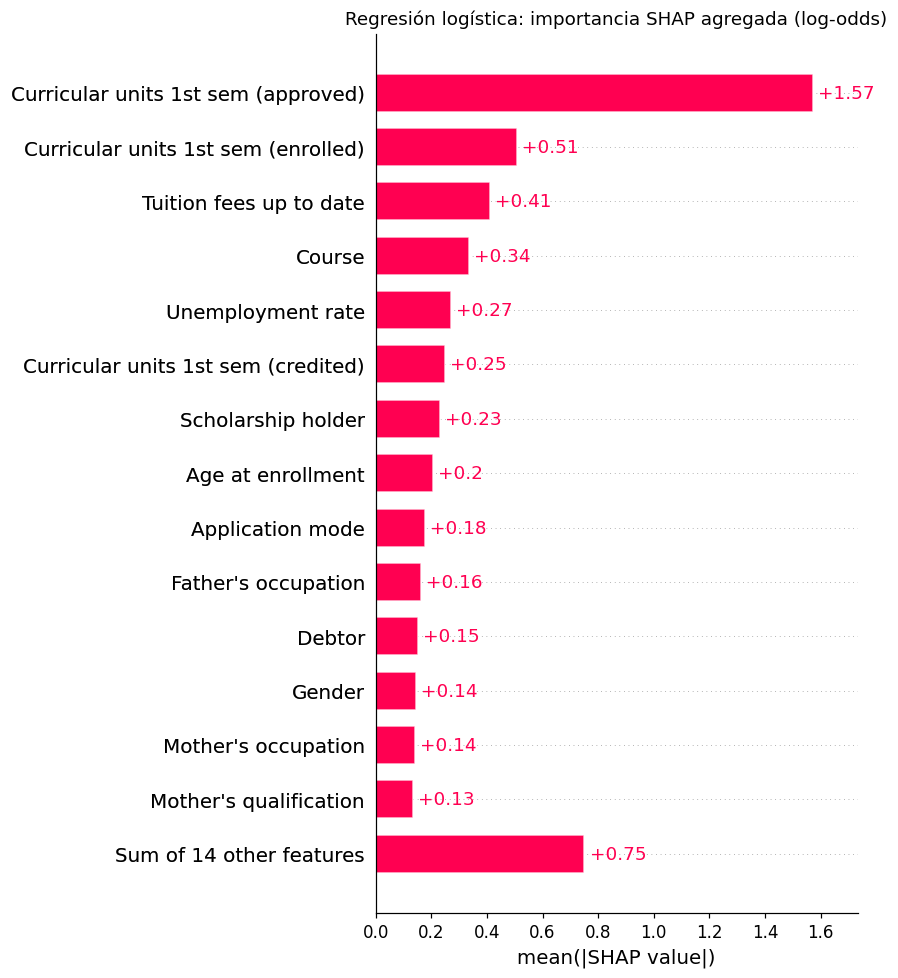

Figura guardada: resultados_tfm/figuras/fig_shap_beeswarm_rl.png


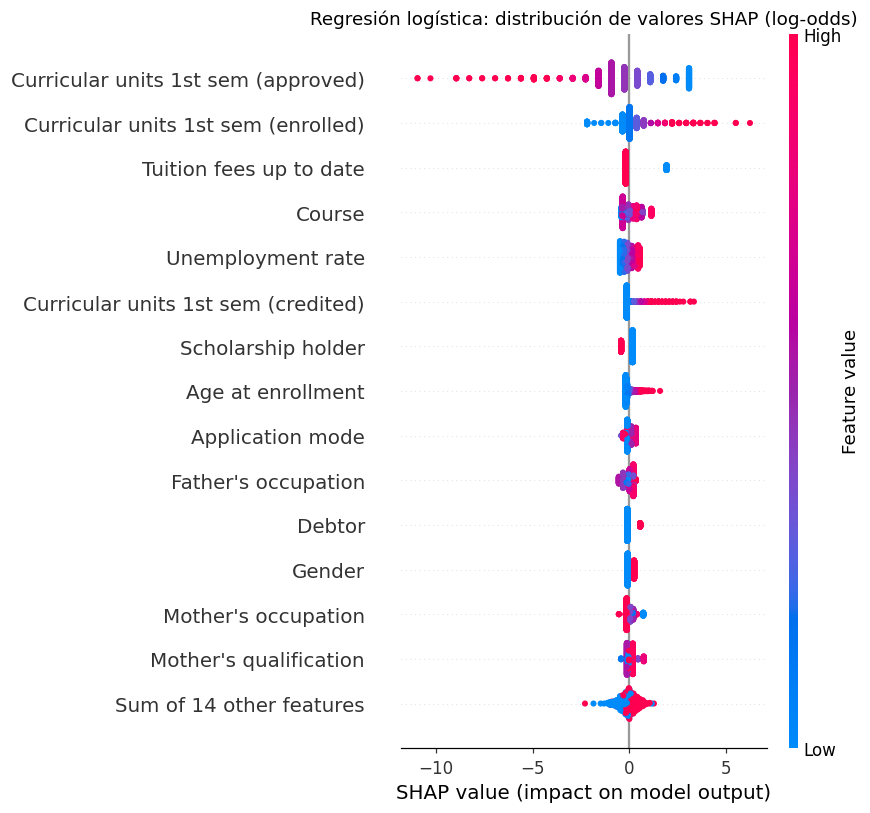

Figura guardada: resultados_tfm/figuras/fig_shap_comparacion_xgb_rl.png


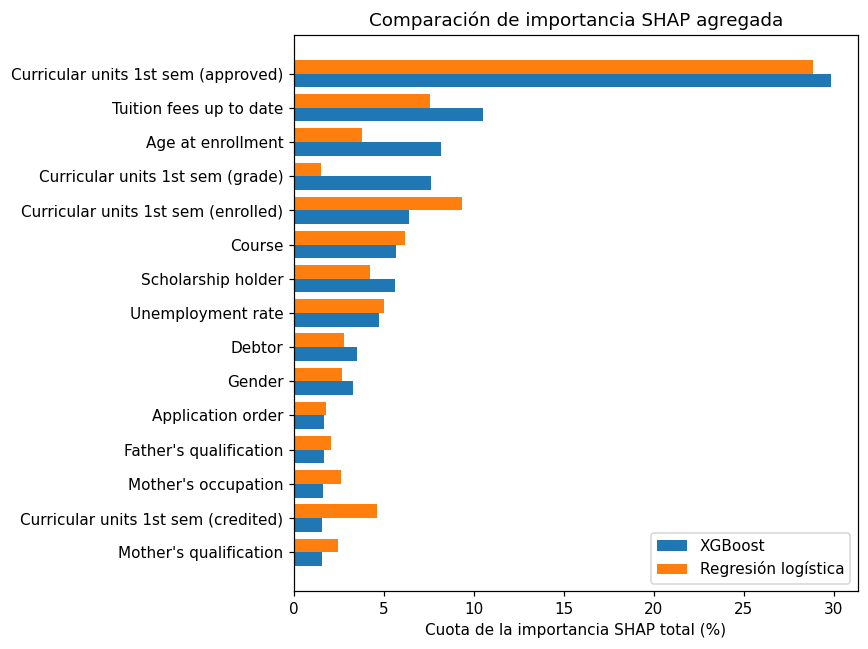

Figura guardada: resultados_tfm/figuras/fig_shap_bar_modelo_seleccionado.png


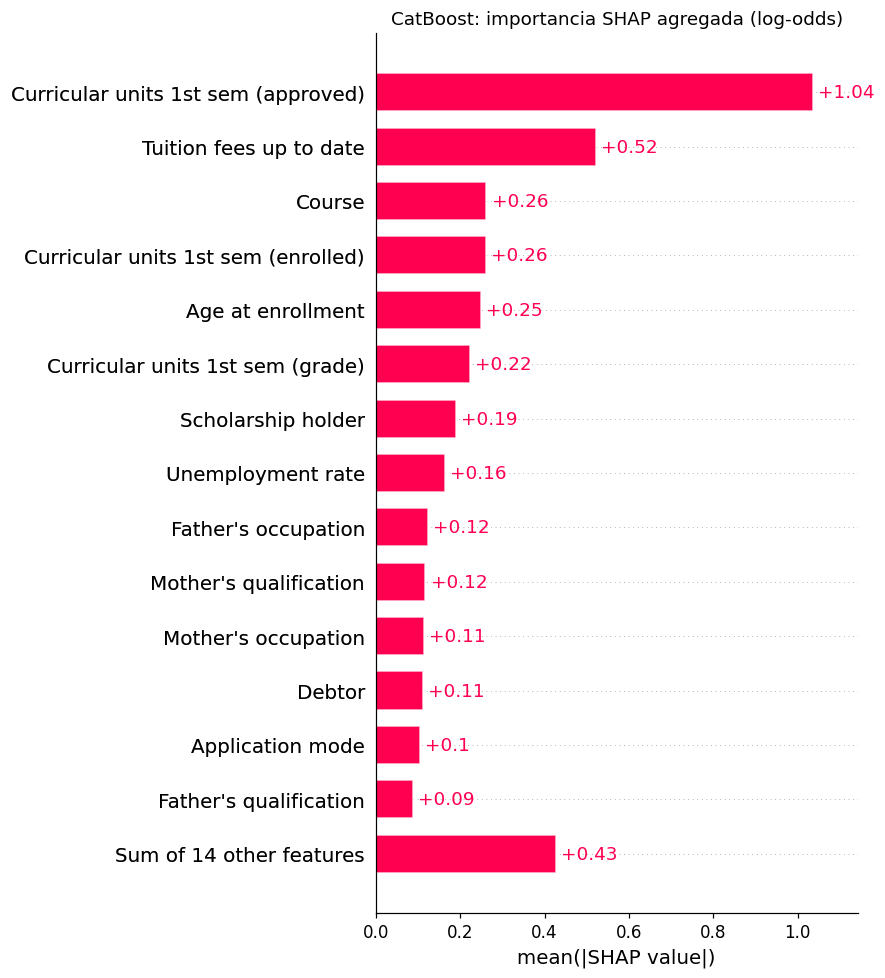

In [ ]:
import shap

def onehot_mapping(preprocessor, cat_cols, num_cols):
    """Devuelve, para cada columna transformada, la variable original de la que procede."""
    enc = preprocessor.named_transformers_["cat"].named_steps["onehot"]
    origin = []
    for col, cats in zip(cat_cols, enc.categories_):
        origin += [col] * len(cats)
    origin += list(num_cols)
    names = preprocessor.get_feature_names_out()
    assert len(origin) == len(names), "La correspondencia One-Hot no coincide con las columnas transformadas"
    return np.array(origin), names

def aggregate_by_original(values, origin, original_order):
    M = np.zeros((len(origin), len(original_order)))
    pos = {c: i for i, c in enumerate(original_order)}
    for r, c in enumerate(origin): M[r, pos[c]] = 1.0
    return values @ M

if RUN_SHAP:
    res = results_by_scenario[MAIN_SCENARIO]; preds = res["predictions"]
    X_train_m, X_test_m = res["X_train"], res["X_test"]
    original_vars = list(X_test_m.columns)
    rng = np.random.default_rng(SEED)
    bg_idx = np.sort(rng.choice(len(X_train_m), size=min(SHAP_BACKGROUND_SIZE, len(X_train_m)), replace=False))

    # ---- XGBoost ----
    xgb_pipe = preds["XGBoost"]["model"]; xgb_pre = xgb_pipe.named_steps["preprocess"]; xgb_est = xgb_pipe.named_steps["model"]
    origin_x, names_x = onehot_mapping(xgb_pre, preds["XGBoost"]["cat_cols"], preds["XGBoost"]["num_cols"])
    Xbg_x = xgb_pre.transform(X_train_m.iloc[bg_idx]); Xte_x = xgb_pre.transform(X_test_m)
    xgb_explainer = shap.TreeExplainer(xgb_est, data=Xbg_x, feature_perturbation="interventional", model_output="probability")
    sv_x = xgb_explainer(Xte_x)
    base_x = float(np.asarray(sv_x.base_values).reshape(-1)[0])
    recon = base_x + sv_x.values.sum(axis=1)
    max_err = np.max(np.abs(recon - xgb_est.predict_proba(Xte_x)[:, 1]))
    print(f"XGBoost: error máximo de aditividad (probabilidad) = {max_err:.2e}")
    agg_x = aggregate_by_original(sv_x.values, origin_x, original_vars)
    exp_x = shap.Explanation(values=agg_x, base_values=np.full(len(agg_x), base_x),
                             data=X_test_m[original_vars].to_numpy(dtype=float), feature_names=original_vars)

    # ---- Regresión logística ----
    lr_pipe = preds["Regresión logística"]["model"]; lr_pre = lr_pipe.named_steps["preprocess"]; lr_est = lr_pipe.named_steps["model"]
    origin_l, names_l = onehot_mapping(lr_pre, preds["Regresión logística"]["cat_cols"], preds["Regresión logística"]["num_cols"])
    Xbg_l = lr_pre.transform(X_train_m.iloc[bg_idx]); Xte_l = lr_pre.transform(X_test_m)
    lr_explainer = shap.LinearExplainer(lr_est, shap.maskers.Independent(Xbg_l, max_samples=len(Xbg_l)))
    sv_l = lr_explainer(Xte_l)
    base_l = float(np.asarray(sv_l.base_values).reshape(-1)[0])
    agg_l = aggregate_by_original(sv_l.values, origin_l, original_vars)
    exp_l = shap.Explanation(values=agg_l, base_values=np.full(len(agg_l), base_l),
                             data=X_test_m[original_vars].to_numpy(dtype=float), feature_names=original_vars)

    # ---- Modelo seleccionado, si no es la regresión logística ni XGBoost ----
    exp_sel, sel_scale = None, None
    if selected_model not in ("Regresión logística", "XGBoost"):
        o_sel = preds[selected_model]; est_sel = o_sel["model"].named_steps["model"]
        if selected_model == "CatBoost":
            from catboost import Pool
            Xp = est_sel._prepare_X(X_test_m)
            sv = est_sel.model_.get_feature_importance(Pool(Xp, cat_features=est_sel.cat_cols_), type="ShapValues")
            agg_s = pd.DataFrame(sv[:, :-1], columns=list(est_sel.feature_names_in_))[original_vars].to_numpy()
            base_s, sel_scale = float(sv[0, -1]), "log-odds"
        else:
            pre_s = o_sel["model"].named_steps["preprocess"]
            origin_s, _ = onehot_mapping(pre_s, o_sel["cat_cols"], o_sel["num_cols"])
            expl_s = shap.TreeExplainer(est_sel, data=pre_s.transform(X_train_m.iloc[bg_idx]),
                                        feature_perturbation="interventional", model_output="probability")
            sv_s = expl_s(pre_s.transform(X_test_m))
            vals = np.asarray(sv_s.values); bv = np.asarray(sv_s.base_values)
            if vals.ndim == 3: vals, bv = vals[:, :, 1], bv[..., 1]
            agg_s = aggregate_by_original(vals, origin_s, original_vars)
            base_s, sel_scale = float(np.ravel(bv)[0]), "probabilidad"
        exp_sel = shap.Explanation(values=agg_s, base_values=np.full(len(agg_s), base_s),
                                   data=X_test_m[original_vars].to_numpy(dtype=float), feature_names=original_vars)
        print(f"SHAP calculado también para el modelo seleccionado ({selected_model}), escala: {sel_scale}")

    # ---- Importancia agregada y comparación ----
    imp = pd.DataFrame({"Variable": original_vars,
                        "Tipo": ["Categórica" if v in categorical_vars else "Numérica/ordinal" for v in original_vars],
                        "Columnas One-Hot": [int((origin_x == v).sum()) for v in original_vars],
                        "|SHAP| medio XGBoost (prob.)": np.abs(agg_x).mean(axis=0),
                        "|SHAP| medio RL (log-odds)": np.abs(agg_l).mean(axis=0)})
    imp["Cuota XGBoost (%)"] = 100 * imp["|SHAP| medio XGBoost (prob.)"] / imp["|SHAP| medio XGBoost (prob.)"].sum()
    imp["Cuota RL (%)"] = 100 * imp["|SHAP| medio RL (log-odds)"] / imp["|SHAP| medio RL (log-odds)"].sum()
    if exp_sel is not None:
        imp[f"|SHAP| medio {selected_model} ({sel_scale})"] = np.abs(exp_sel.values).mean(axis=0)
        imp[f"Rango {selected_model}"] = imp[f"|SHAP| medio {selected_model} ({sel_scale})"].rank(ascending=False).astype(int)
    imp["Rango XGBoost"] = imp["|SHAP| medio XGBoost (prob.)"].rank(ascending=False).astype(int)
    imp["Rango RL"] = imp["|SHAP| medio RL (log-odds)"].rank(ascending=False).astype(int)
    imp = imp.sort_values("Rango XGBoost")
    display(imp.round(4)); save_table(imp, "tabla_importancia_shap_agregada")

    rho, p_rho = spearmanr(imp["Rango XGBoost"], imp["Rango RL"])
    top10_x = set(imp.nsmallest(10, "Rango XGBoost")["Variable"]); top10_l = set(imp.nsmallest(10, "Rango RL")["Variable"])
    shap_comparison = {"rho_spearman_rangos": float(rho), "p_valor": float(p_rho),
                       "coincidencias_top10": len(top10_x & top10_l), "comunes_top10": sorted(top10_x & top10_l),
                       "solo_XGBoost_top10": sorted(top10_x - top10_l), "solo_RL_top10": sorted(top10_l - top10_x)}
    print(json.dumps(shap_comparison, indent=2, ensure_ascii=False))
    (TAB_DIR / "comparacion_shap_xgb_rl.json").write_text(json.dumps(shap_comparison, indent=2, ensure_ascii=False), encoding="utf-8")

    # ---- Figuras ----
    plt.figure(); shap.plots.bar(exp_x, max_display=15, show=False)
    plt.title("XGBoost: importancia SHAP agregada por variable original"); plt.tight_layout(); save_fig("fig_shap_bar_xgboost_agregado"); plt.show(); plt.close("all")
    plt.figure(); shap.plots.beeswarm(exp_x, max_display=15, show=False)
    plt.title("XGBoost: distribución de valores SHAP (probabilidad)"); plt.tight_layout(); save_fig("fig_shap_beeswarm_xgboost"); plt.show(); plt.close("all")
    plt.figure(); shap.plots.bar(exp_l, max_display=15, show=False)
    plt.title("Regresión logística: importancia SHAP agregada (log-odds)"); plt.tight_layout(); save_fig("fig_shap_bar_rl_agregado"); plt.show(); plt.close("all")
    plt.figure(); shap.plots.beeswarm(exp_l, max_display=15, show=False)
    plt.title("Regresión logística: distribución de valores SHAP (log-odds)"); plt.tight_layout(); save_fig("fig_shap_beeswarm_rl"); plt.show(); plt.close("all")

    top = imp.nsmallest(15, "Rango XGBoost").iloc[::-1]
    ypos = np.arange(len(top))
    plt.figure(figsize=(8, 6))
    plt.barh(ypos - 0.2, top["Cuota XGBoost (%)"], height=0.4, label="XGBoost")
    plt.barh(ypos + 0.2, top["Cuota RL (%)"], height=0.4, label="Regresión logística")
    plt.yticks(ypos, top["Variable"]); plt.xlabel("Cuota de la importancia SHAP total (%)")
    plt.title("Comparación de importancia SHAP agregada"); plt.legend(); plt.tight_layout()
    save_fig("fig_shap_comparacion_xgb_rl"); plt.show(); plt.close("all")

    if exp_sel is not None:
        plt.figure(); shap.plots.bar(exp_sel, max_display=15, show=False)
        plt.title(f"{selected_model}: importancia SHAP agregada ({sel_scale})"); plt.tight_layout()
        save_fig("fig_shap_bar_modelo_seleccionado"); plt.show(); plt.close("all")

    # Columnas One-Hot sin agregar
    imp_raw = pd.DataFrame({"Columna transformada": names_x, "|SHAP| medio": np.abs(sv_x.values).mean(axis=0)}).nlargest(15, "|SHAP| medio")
    save_table(imp_raw, "tabla_importancia_shap_xgb_sin_agregar")

## 13. Interpretabilidad local: verdadero positivo, falso negativo y caso cercano al umbral

Se eligen tres estudiantes del conjunto de prueba según las predicciones de XGBoost con su umbral final:
- **Verdadero positivo típico**: el `Dropout` detectado cuya probabilidad está más cerca de la mediana de los verdaderos positivos.
- **Falso negativo típico**: el `Dropout` no detectado más cercano a la mediana de los falsos negativos.
- **Caso cercano al umbral**: la observación restante con la probabilidad más próxima al umbral.

Para cada caso se guarda el gráfico de cascada (agregado por variable original) y una tabla con las cinco contribuciones principales y los valores reales de esas variables. Los mismos casos se explican con la regresión logística.

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_verdadero_positivo_xgboost.png


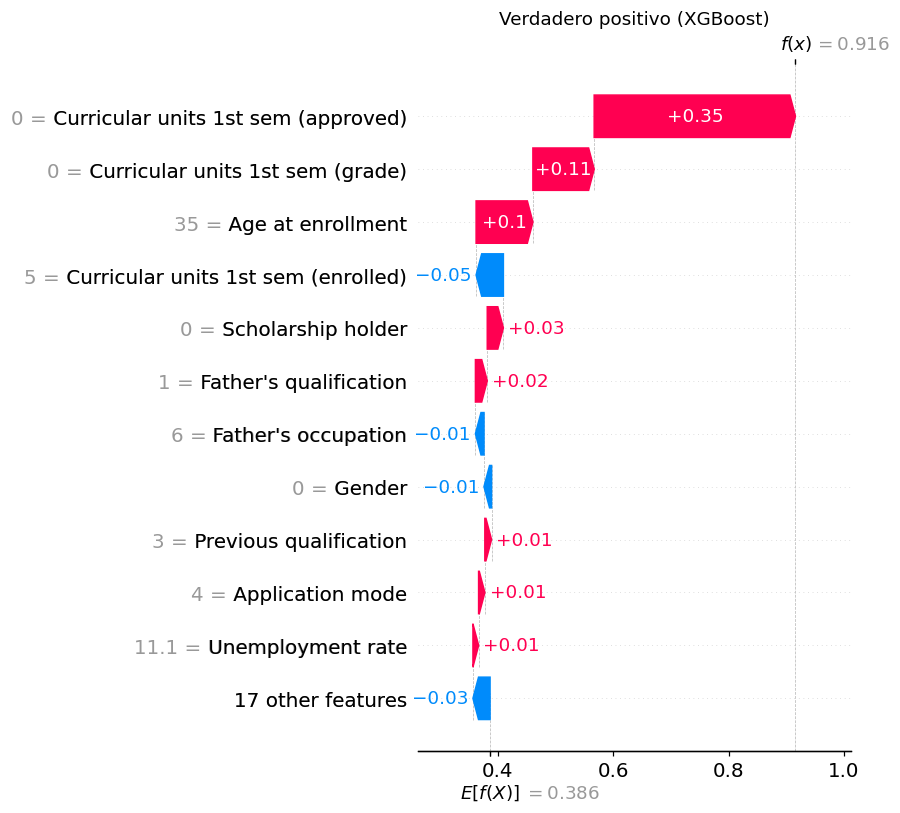

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_verdadero_positivo_rl.png


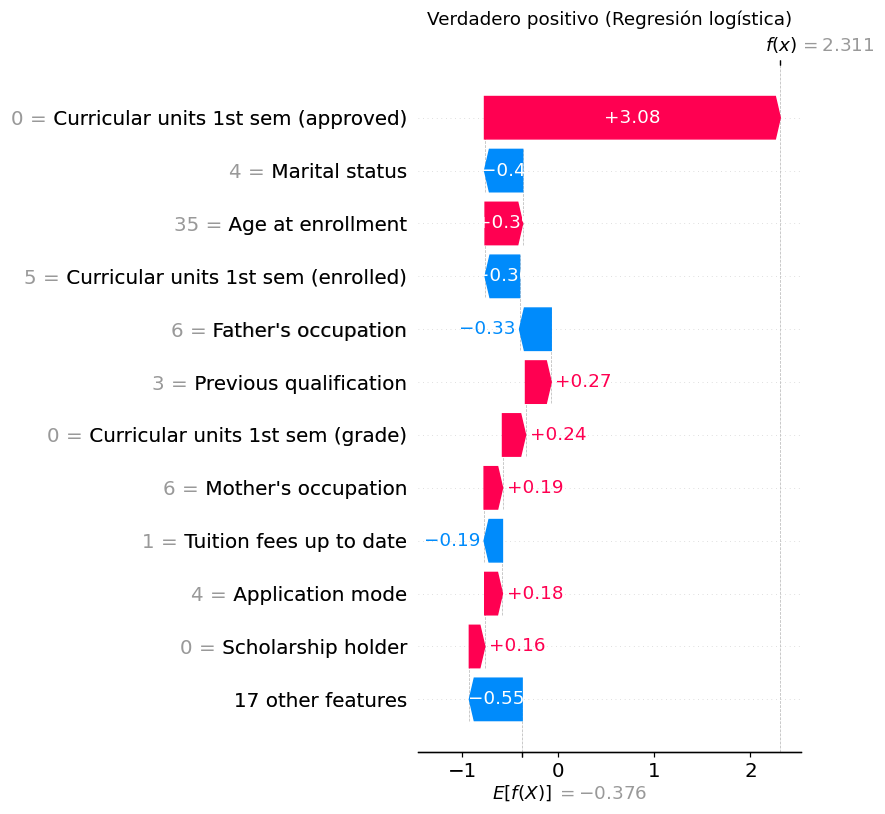

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_verdadero_positivo_seleccionado.png


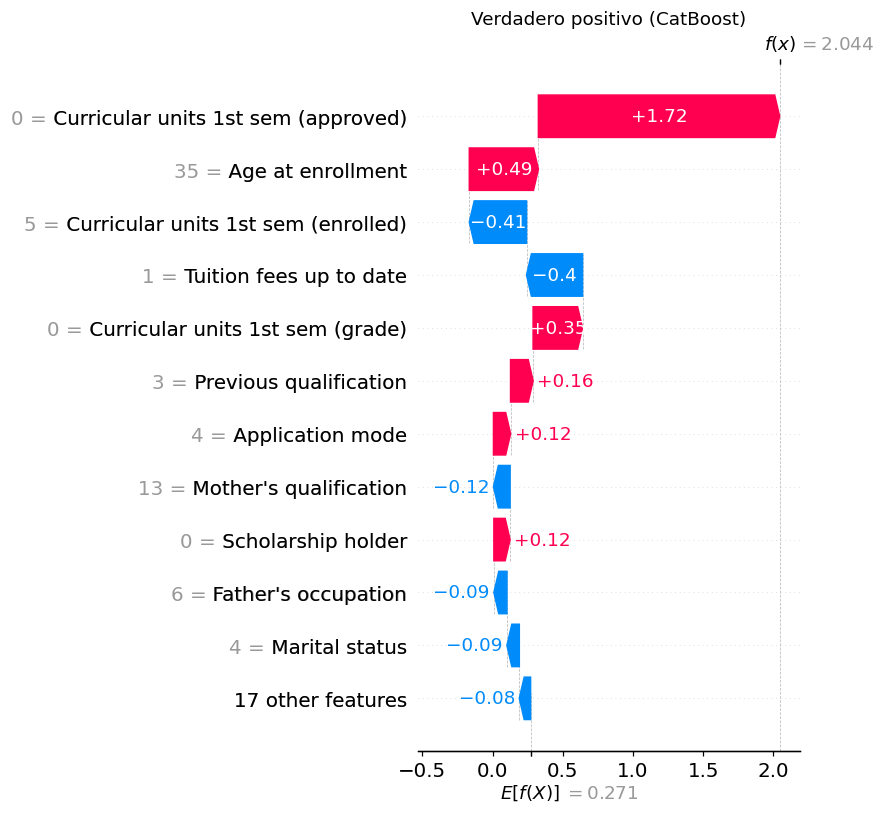

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_falso_negativo_xgboost.png


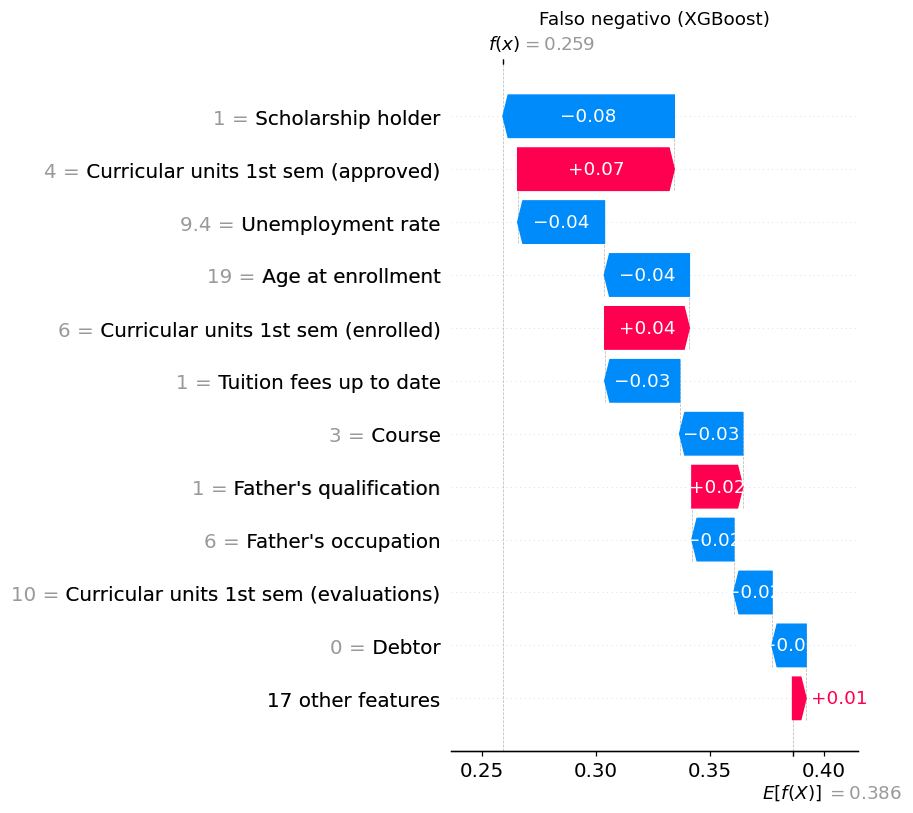

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_falso_negativo_rl.png


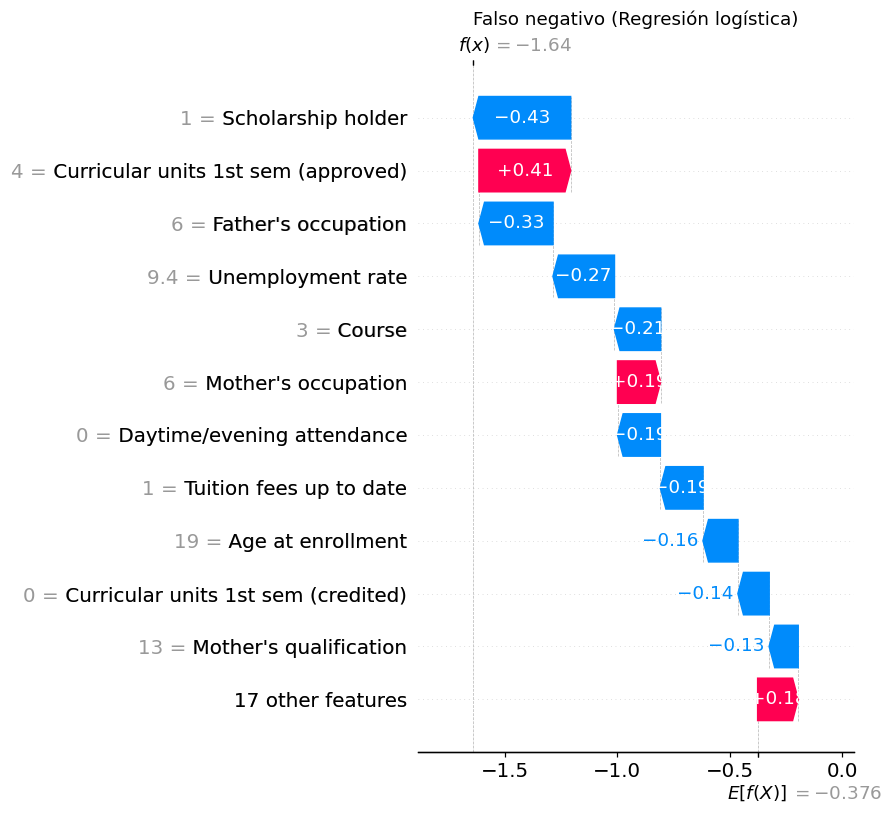

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_falso_negativo_seleccionado.png


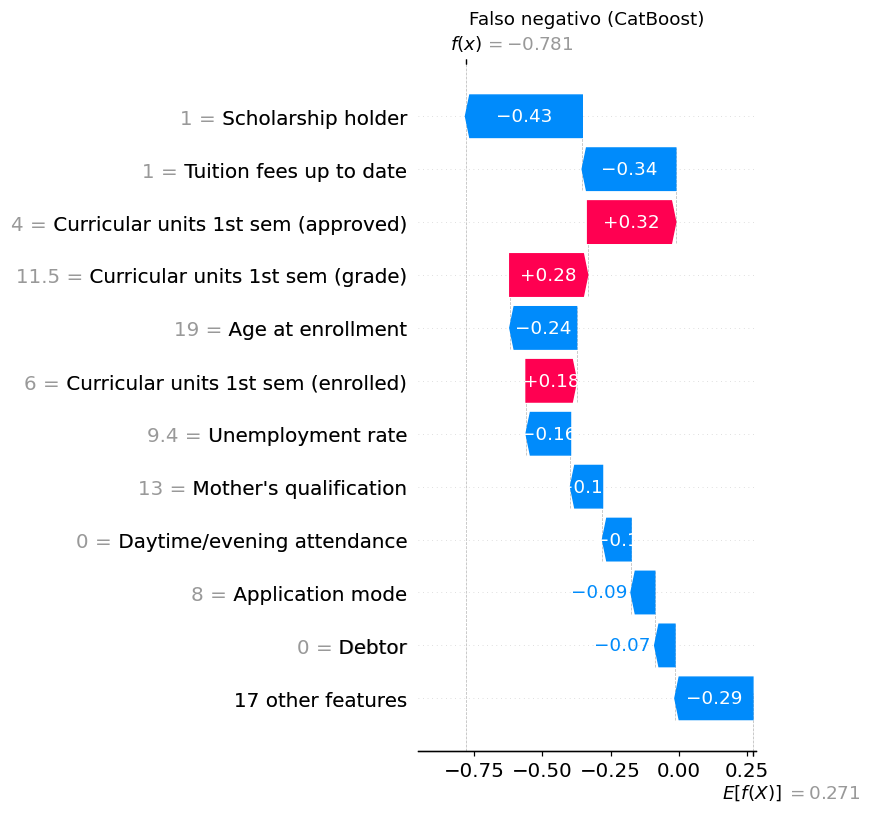

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_caso_umbral_xgboost.png


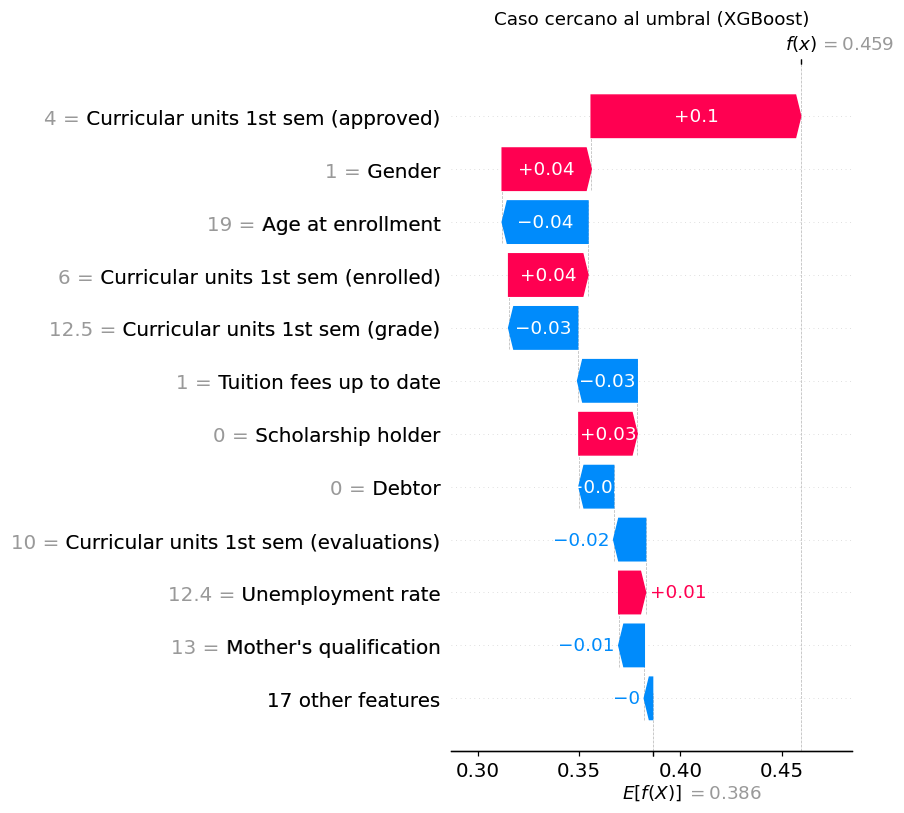

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_caso_umbral_rl.png


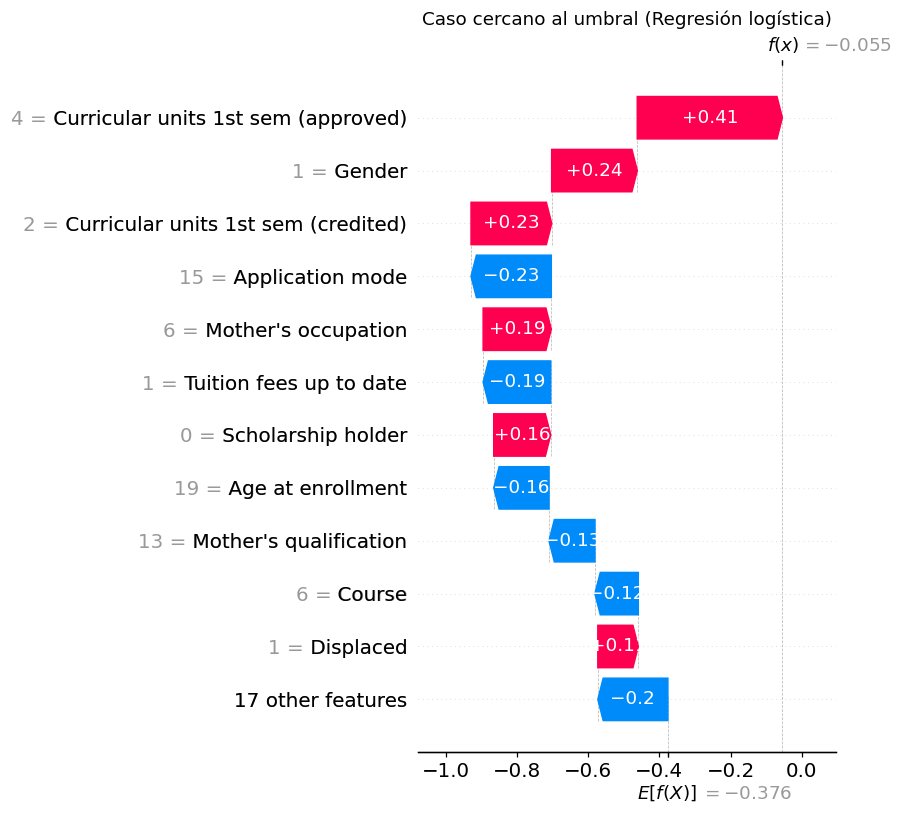

Figura guardada: resultados_tfm/figuras/fig_shap_waterfall_caso_umbral_seleccionado.png


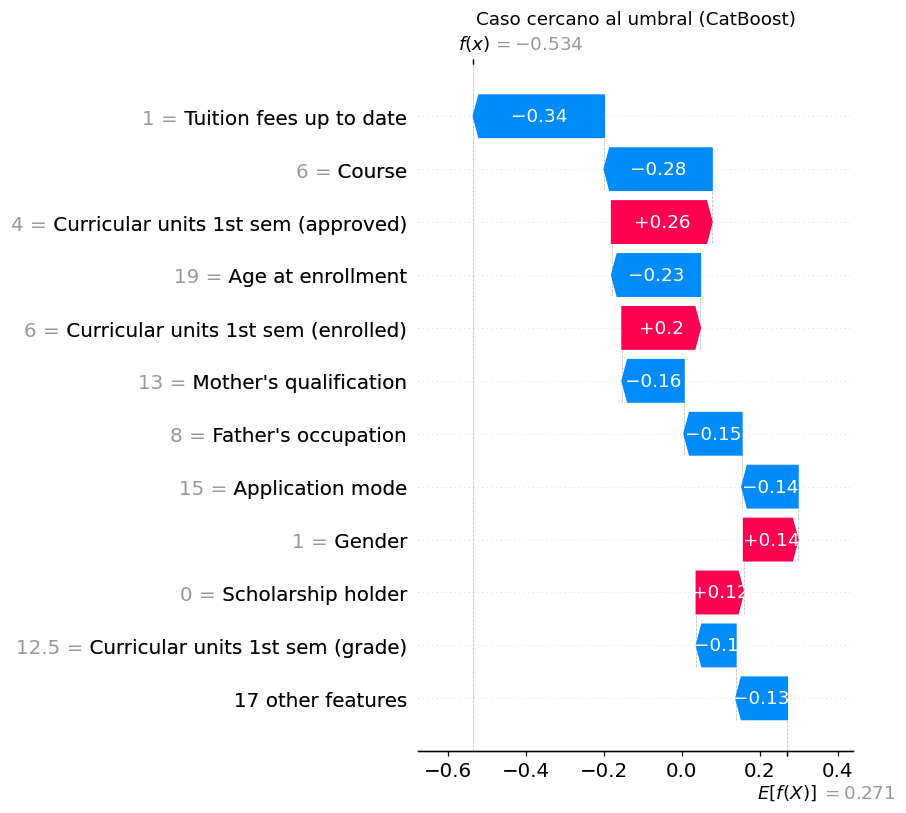

,Caso,Índice en prueba,Clase real,Prob. XGBoost,Umbral XGBoost,Predicción XGBoost,Prob. RL,Umbral RL,Predicción RL,Valor base XGBoost,Top 5 contribuciones XGBoost
0,Verdadero positivo,414,Dropout,0.915765,0.46,1,0.90975,0.485,1,0.386269,Curricular units 1st sem (approved) = 0 (+0.349); Curricular units 1st sem (grade) = 0 (+0.106); Age at enrollment = 35 (+0.098); Curricular units 1st sem (enrolled) = 5 (-0.047); Scholarship holder = 0 (+0.028)
1,Falso negativo,268,Dropout,0.259250,0.46,0,0.16253,0.485,0,0.386269,Scholarship holder = 1 (-0.075); Curricular units 1st sem (approved) = 4 (+0.069); Unemployment rate = 9.4 (-0.038); Age at enrollment = 19 (-0.037); Curricular units 1st sem (enrolled) = 6 (+0.037)
2,Caso cercano al umbral,802,Dropout,0.459381,0.46,0,0.48630,0.485,1,0.386269,Curricular units 1st sem (approved) = 4 (+0.103); Gender = 1 (+0.044); Age at enrollment = 19 (-0.042); Curricular units 1st sem (enrolled) = 6 (+0.039); Curricular units 1st sem (grade) = 12.5 (-0.034)


In [ ]:
if RUN_SHAP:
    o = preds["XGBoost"]; ytest = np.asarray(o["y_test"]); prob = o["prob"]; thr = o["threshold"]; pred = o["pred"]
    def pick_median(idx):
        return int(idx[np.argmin(np.abs(prob[idx] - np.median(prob[idx])))]) if len(idx) else None
    tp_idx = pick_median(np.where((ytest == 1) & (pred == 1))[0])
    fn_idx = pick_median(np.where((ytest == 1) & (pred == 0))[0])
    rest = np.array([i for i in range(len(ytest)) if i not in {tp_idx, fn_idx}])
    border_idx = int(rest[np.argmin(np.abs(prob[rest] - thr))])
    cases = [("verdadero_positivo", "Verdadero positivo", tp_idx), ("falso_negativo", "Falso negativo", fn_idx),
             ("caso_umbral", "Caso cercano al umbral", border_idx)]

    local_rows = []
    lr_prob = preds["Regresión logística"]["prob"]; lr_thr = preds["Regresión logística"]["threshold"]
    for slug, label, idx in cases:
        if idx is None:
            print("Sin candidato para", label); continue
        explained = [("XGBoost", exp_x, f"fig_shap_waterfall_{slug}_xgboost"),
                     ("Regresión logística", exp_l, f"fig_shap_waterfall_{slug}_rl")]
        if exp_sel is not None:
            explained.append((selected_model, exp_sel, f"fig_shap_waterfall_{slug}_seleccionado"))
        for model_name, exp_obj, fname in explained:
            plt.figure(); shap.plots.waterfall(exp_obj[idx], max_display=12, show=False)
            plt.title(f"{label} ({model_name})"); plt.tight_layout(); save_fig(fname); plt.show(); plt.close("all")
        contrib = pd.Series(exp_x.values[idx], index=original_vars)
        top5 = contrib.reindex(contrib.abs().sort_values(ascending=False).index[:5])
        local_rows.append({"Caso": label, "Índice en prueba": idx, "Clase real": "Dropout" if ytest[idx] == 1 else "No abandono",
                           "Prob. XGBoost": prob[idx], "Umbral XGBoost": thr, "Predicción XGBoost": int(pred[idx]),
                           "Prob. RL": lr_prob[idx], "Umbral RL": lr_thr, "Predicción RL": int(lr_prob[idx] >= lr_thr),
                           "Valor base XGBoost": base_x,
                           "Top 5 contribuciones XGBoost": "; ".join(f"{v} = {X_test_m.iloc[idx][v]:g} ({c:+.3f})" for v, c in top5.items())})
    casos_locales = pd.DataFrame(local_rows)
    pd.set_option("display.max_colwidth", 300); display(casos_locales)
    save_table(casos_locales, "tabla_casos_shap_locales")

## 14. Análisis de equidad por género y grupo de edad

Se compara en prueba la sensibilidad (igualdad de oportunidades), la tasa de falsos positivos y la precisión por grupo. Las diferencias son descriptivas; los grupos pequeños producen estimaciones inestables, por lo que se informa del tamaño de cada grupo.

In [ ]:
res = results_by_scenario[MAIN_SCENARIO]; X_test_m = res["X_test"]; ytest = np.asarray(res["y_test"])
groups = {"Género": X_test_m["Gender"].map({0: "Mujer", 1: "Hombre"}),
          "Edad al matricularse": pd.cut(X_test_m["Age at enrollment"], bins=[0, 20, 25, 200], labels=["≤ 20", "21 a 25", "≥ 26"])}
eq_rows = []
for model_name in MODEL_ORDER:
    pred = res["predictions"][model_name]["pred"]
    for gname, g in groups.items():
        for level in g.dropna().unique():
            mask = (g == level).to_numpy()
            yt, yp = ytest[mask], pred[mask]
            tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
            eq_rows.append({"Modelo": model_name, "Atributo": gname, "Grupo": str(level), "n": int(mask.sum()),
                            "Dropout reales": int(yt.sum()), "Sensibilidad": tp / (tp + fn) if tp + fn else np.nan,
                            "Tasa falsos positivos": fp / (fp + tn) if fp + tn else np.nan,
                            "Precisión": tp / (tp + fp) if tp + fp else np.nan})
equity = pd.DataFrame(eq_rows)
gap = (equity.groupby(["Modelo", "Atributo"])
       .agg(**{"Brecha de sensibilidad (máx − mín)": ("Sensibilidad", lambda s: s.max() - s.min()),
               "Brecha de FPR (máx − mín)": ("Tasa falsos positivos", lambda s: s.max() - s.min())}).reset_index())
display(equity.round(3)); display(gap.round(3))
save_table(equity, "tabla_equidad", decimals=3); save_table(gap, "tabla_equidad_brechas", decimals=3)

,Modelo,Atributo,Grupo,n,Dropout reales,Sensibilidad,Tasa falsos positivos,Precisión
0,Regresión logística,Género,Mujer,564,138,0.790,0.106,0.708
1,Regresión logística,Género,Hombre,321,146,0.877,0.200,0.785
2,Regresión logística,Edad al matricularse,≤ 20,513,102,0.755,0.100,0.653
3,Regresión logística,Edad al matricularse,≥ 26,215,126,0.921,0.247,0.841
4,Regresión logística,Edad al matricularse,21 a 25,157,56,0.786,0.168,0.721
5,Árbol de decisión,Género,Mujer,564,138,0.819,0.223,0.543
6,Árbol de decisión,Género,Hombre,321,146,0.849,0.326,0.685
7,Árbol de decisión,Edad al matricularse,≤ 20,513,102,0.775,0.221,0.465
8,Árbol de decisión,Edad al matricularse,≥ 26,215,126,0.889,0.292,0.812
9,Árbol de decisión,Edad al matricularse,21 a 25,157,56,0.821,0.347,0.568


,Modelo,Atributo,Brecha de sensibilidad (máx − mín),Brecha de FPR (máx − mín)
0,CatBoost,Edad al matricularse,0.208,0.185
1,CatBoost,Género,0.009,0.090
2,Random Forest,Edad al matricularse,0.236,0.150
3,Random Forest,Género,0.075,0.128
4,Regresión logística,Edad al matricularse,0.166,0.147
5,Regresión logística,Género,0.087,0.094
6,XGBoost,Edad al matricularse,0.193,0.096
7,XGBoost,Género,0.010,0.104
8,Árbol de decisión,Edad al matricularse,0.114,0.125
9,Árbol de decisión,Género,0.030,0.103


## 15. Exportación de resultados, configuración y entorno

In [ ]:
import sklearn, scipy, xgboost, catboost, imblearn, statsmodels
cv_all.to_csv(OUTPUT_DIR / "validacion_cruzada_anidada.csv", index=False)
test_all.to_csv(OUTPUT_DIR / "resultados_prueba.csv", index=False)
params_all.to_csv(OUTPUT_DIR / "hiperparametros_y_umbrales.csv", index=False)
folds_all.to_csv(OUTPUT_DIR / "pliegues_externos.csv", index=False)

versions = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "imbalanced-learn": imblearn.__version__, "scipy": scipy.__version__,
            "xgboost": xgboost.__version__, "catboost": catboost.__version__,
            "shap": (shap.__version__ if RUN_SHAP else None), "statsmodels": statsmodels.__version__,
            "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
config = {"seed": SEED, "test_size": TEST_SIZE, "n_outer": N_OUTER, "n_inner": N_INNER, "n_iter": N_ITER,
          "threshold_cv_final": THRESHOLD_CV_FINAL, "threshold_cv_nested": THRESHOLD_CV_NESTED,
          "threshold_grid": "0,05 a 0,95, paso 0,005", "balance_strategy": BALANCE_STRATEGY,
          "scenarios": SCENARIOS, "main_scenario": MAIN_SCENARIO, "fast_mode": FAST_MODE,
          "dataset_source": DATA_SOURCE, "dataset_sha256": source_sha256, "selected_model": selected_model,
          "versions": versions}
(OUTPUT_DIR / "entorno_y_configuracion.json").write_text(json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8")

# requirements.txt con las versiones exactas de las librerías principales y pip freeze completo aparte.
req_names = {"numpy": "numpy", "pandas": "pandas", "scikit-learn": "scikit-learn", "imbalanced-learn": "imbalanced-learn",
             "scipy": "scipy", "xgboost": "xgboost", "catboost": "catboost", "shap": "shap", "statsmodels": "statsmodels",
             "matplotlib": "matplotlib", "seaborn": "seaborn"}
(OUTPUT_DIR / "requirements.txt").write_text("\n".join(f"{req_names[k]}=={v}" for k, v in versions.items() if k in req_names and v) + "\n", encoding="utf-8")
try:
    (OUTPUT_DIR / "requirements_pip_freeze.txt").write_text(subprocess.check_output([sys.executable, "-m", "pip", "freeze"], text=True), encoding="utf-8")
except Exception as e:
    print("No se pudo ejecutar pip freeze:", e)

print(json.dumps(config, indent=2, ensure_ascii=False))
print("\nArchivos generados:")
for p in sorted(OUTPUT_DIR.rglob("*")):
    if p.is_file(): print(" ", p)

# Empaquetado para descargar desde Colab
import shutil
shutil.make_archive("resultados_tfm", "zip", OUTPUT_DIR)
print("\nDescargue resultados_tfm.zip")

{
  "seed": 42,
  "test_size": 0.2,
  "n_outer": 10,
  "n_inner": 3,
  "n_iter": 10,
  "threshold_cv_final": 5,
  "threshold_cv_nested": 3,
  "threshold_grid": "0,05 a 0,95, paso 0,005",
  "balance_strategy": "oversampling",
  "scenarios": [
    "at_enrollment",
    "after_first_semester",
    "after_second_semester"
  ],
  "main_scenario": "after_first_semester",
  "fast_mode": false,
  "dataset_source": "Kaggle: thedevastator/higher-education-predictors-of-student-retention (dataset.csv)",
  "dataset_sha256": "3e9093c2a14254ba3b6851e13204dd53d31f43a63570d8ed61763c23a7a91abf",
  "selected_model": "CatBoost",
  "versions": {
    "python": "3.13.18",
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "imbalanced-learn": "0.13.0",
    "scipy": "1.16.3",
    "xgboost": "3.4.1",
    "catboost": "1.2.10",
    "shap": "0.54.1",
    "statsmodels": "0.14.5",
    "matplotlib": "3.10.0",
    "seaborn": "0.13.2"
  }
}

Archivos generados:
  resultados_tfm/entorno_y_conf